# Isotope Peak Detection in NIST20

Validates `detect_isotope_peaks` (the naive detector, defined in this notebook) on the NIST20 reference dataset.

**Questions answered:**
- What fraction of spectra contain isotope peaks?
- What fraction of all peaks are isotope peaks?
- How does this break down by instrument type, fragmentation mode, and precursor type?
- How sensitive are results to `mz_tol` and `check_intensity` settings?
- How do naive vs formula-aware detection compare?

In [23]:
import gc
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

sys.path.insert(0, "../src")
# The naive fixed-spacing detector (k * C13_SPACING), removed from fragnnet.utils.isotope_utils
# on 2026-10-12; kept here so this analysis still runs.
import numpy as np

from fragnnet.utils.formula_utils import C13_SPACING


def detect_isotope_peaks(
    mzs: np.ndarray,
    ints: np.ndarray,
    mz_tol: float = 0.02,
    max_isotope: int = 3,
    check_intensity: bool = True,
) -> np.ndarray:
    """Detect isotope peaks in a reference spectrum.

    A peak is considered an isotope peak (M+k, k >= 1) if there exists a
    lower-m/z peak separated by approximately k * C13_SPACING within
    ``mz_tol``.  Optionally, that lower-m/z peak must also be more intense
    than the candidate isotope peak.

    The function works with raw (non-normalised) m/z and intensity arrays as
    produced by standard reference libraries such as NIST.

    Args:
        mzs: Peak m/z values of shape (N,).  Need not be sorted.
        ints: Peak intensities of shape (N,).  Same order as ``mzs``.
        mz_tol: Absolute m/z tolerance in Da for matching isotope spacing.
            The step is centred on the exact 13C–12C spacing (C13_SPACING,
            ~1.0034 Da); the default of 0.02 Da also tolerates the slightly
            larger neutron-mass spacing (~1.0087 Da).  Defaults to 0.02.
        max_isotope: Maximum isotope order to consider (1 = M+1 only,
            2 = up to M+2, etc.). Defaults to 3.
        check_intensity: If True, require that the candidate monoisotopic
            peak (the one at mz - k * NEUTRON_MASS) is at least as intense
            as the current peak.  This suppresses false positives from
            noise but may miss isotope peaks of low-intensity fragments.
            Defaults to True.

    Returns:
        Boolean array of shape (N,) where True means the peak is an
        isotope peak.

    Example:
        >>> mzs = np.array([100.0, 101.008, 200.0, 201.012])
        >>> ints = np.array([1000.0, 100.0, 500.0, 50.0])
        >>> mask = detect_isotope_peaks(mzs, ints)
        >>> mask  # peaks at 101.008 and 201.012 flagged as isotopes
        array([False,  True, False,  True])
    """
    mzs = np.asarray(mzs, dtype=np.float64)
    ints = np.asarray(ints, dtype=np.float64)
    if mzs.shape != ints.shape or mzs.ndim != 1:
        raise ValueError(f"mzs and ints must be 1-D arrays of the same length, got {mzs.shape}")

    n = len(mzs)
    is_isotope = np.zeros(n, dtype=bool)
    if n == 0:
        return is_isotope

    sort_idx = np.argsort(mzs)
    sorted_mzs = mzs[sort_idx]
    sorted_ints = ints[sort_idx]

    for i in range(n):
        for k in range(1, max_isotope + 1):
            target_mz = sorted_mzs[i] - k * C13_SPACING
            lo = np.searchsorted(sorted_mzs, target_mz - mz_tol, side="left")
            hi = np.searchsorted(sorted_mzs, target_mz + mz_tol, side="right")
            if lo >= hi:
                continue
            # At least one candidate monoisotopic peak exists in the window.
            if check_intensity:
                if np.any(sorted_ints[lo:hi] >= sorted_ints[i]):
                    is_isotope[sort_idx[i]] = True
                    break
            else:
                is_isotope[sort_idx[i]] = True
                break

    return is_isotope

PROC_DP = Path("../data/proc")
SAMPLE_N = 100_000   # spectra per dataset; set to None to use all
RANDOM_SEED = 42

SPEC_COLS = ["spec_id", "mol_id", "inst_type", "frag_mode", "prec_type",
             "ion_mode", "ace", "nce", "prec_mz", "peaks"]

## Helper — per-spectrum isotope stats

In [24]:
import math
import re
from functools import lru_cache

NEUTRON_MASS = 1.008665  # same constant as spec_utils

# Natural abundance M+1/M+0 contribution per atom (used for k=1 and as base for k>1)
_M1_PER_ATOM: dict[str, float] = {
    "C": 0.01103,   # 13C
    "H": 0.000149,  # 2H
    "N": 0.00368,   # 15N
    "O": 0.000404,  # 17O
    "S": 0.00421,   # 33S
    "Si": 0.04683,  # 29Si
}

# Additive M+2/M+0 contributions per atom from heavy isotopes
# K added: 41K natural abundance 6.73% — critical for [M+K]+ adduct spectra
_M2_ADDITIVE_PER_ATOM: dict[str, float] = {
    "Cl": 0.3220,   # 37Cl/35Cl — dominant for Cl compounds
    "Br": 0.9735,   # 81Br/79Br — dominant for Br compounds
    "K":  0.0673,   # 41K — present in [M+K]+ fragment ions
    "S":  0.0425,   # 34S
    "Si": 0.0337,   # 30Si
    "O":  0.00204,  # 18O
}

# Positive atom counts added by each adduct type (mirrors PREC_TYPE_TO_FORMULA_DIFF,
# positive entries only — these atoms are retained in fragment ions and contribute
# their own isotope signature at full weight, unlike molecule atoms which scale with
# fragment size).
_ADDUCT_ATOM_COUNTS: dict[str, dict[str, int]] = {
    "[M+H]+":         {"H": 1},
    "[M+Na]+":        {"Na": 1},
    "[M+K]+":         {"K": 1},
    "[M+NH4]+":       {"N": 1, "H": 4},
    "[M+H+2i]+":      {"H": 1, "I": 2},
    "[M+Cl]-":        {"Cl": 1},
    "[M+CH3COO]-":    {"C": 2, "H": 3, "O": 2},
    "[M+CH3COOH-H]-": {"C": 2, "H": 3, "O": 2},
    "[M+HCOOH-H]-":   {"C": 1, "H": 2, "O": 2},
    "[M+CH2O2-H]-":   {"C": 1, "H": 2, "O": 2},
}


@lru_cache(maxsize=8192)
def _parse_formula(formula: str) -> tuple[tuple[str, int], ...]:
    return tuple(
        (elem, int(count) if count else 1)
        for elem, count in re.findall(r"([A-Z][a-z]?)(\d*)", formula)
    )


def expected_m1_ratio(formula: str) -> float:
    counts = dict(_parse_formula(formula))
    return sum(counts.get(elem, 0) * contrib for elem, contrib in _M1_PER_ATOM.items())


def expected_mk_ratio(
    formula: str,
    scale: float,
    k: int,
    prec_type: str | None = None,
) -> float:
    """Expected M+k / M+0 intensity ratio for a fragment, adduct-aware.

    Molecule atoms are scaled by ``scale`` (≈ neutral fragment mass / neutral
    precursor mass).  Adduct atoms (e.g. K from ``[M+K]+``) are applied at
    **full weight**: the charge carrier either stays with the fragment entirely
    or is absent — it does not distribute proportionally the way carbon does.

    Args:
        formula: Precursor molecular formula.
        scale: Approximate neutral-mass fraction of the precursor in this
            fragment — ``(frag_mz - adduct_mass) / (prec_mz - adduct_mass)``.
        k: Isotope order (1 = M+1, 2 = M+2).
        prec_type: Adduct/precursor type string (e.g. ``"[M+K]+"``,
            ``"[M+Cl]-"``).  When provided, atoms added by the adduct are
            included in the ratio prediction at full weight.

    Returns:
        Expected M+k/M+0 intensity ratio, floored at 1e-4.
    """
    mol_counts = dict(_parse_formula(formula))
    adduct_counts = _ADDUCT_ATOM_COUNTS.get(prec_type, {}) if prec_type else {}

    m1_mol = sum(mol_counts.get(elem, 0) * c for elem, c in _M1_PER_ATOM.items())
    m1_add = sum(adduct_counts.get(elem, 0) * c for elem, c in _M1_PER_ATOM.items())
    total_m1 = m1_mol * scale + m1_add
    poisson_term = total_m1 ** k / math.factorial(k)
    if k == 2:
        m2_mol = sum(mol_counts.get(elem, 0) * c for elem, c in _M2_ADDITIVE_PER_ATOM.items())
        m2_add = sum(adduct_counts.get(elem, 0) * c for elem, c in _M2_ADDITIVE_PER_ATOM.items())
        return max(poisson_term + m2_mol * scale + m2_add, 1e-4)
    return max(poisson_term, 1e-4)


def detect_isotope_peaks_formula_aware(
    mzs: np.ndarray,
    ints: np.ndarray,
    prec_mz: float,
    formula: str,
    prec_type: str | None = None,
    mz_tol: float = 0.02,
    max_isotope: int = 2,
    lo_factor: float = 0.3,
    hi_factor: float = 3.0,
) -> np.ndarray:
    """Formula- and adduct-aware isotope peak detection (exploratory, wide tolerance).

    Adduct atoms (K, Cl, etc.) are applied at full weight; the mol_scale is
    corrected by subtracting the adduct atom mass from both fragment and precursor.
    """
    from fragnnet.utils.formula_utils import MASS, PREC_TYPE_TO_FORMULA_DIFF
    mzs = np.asarray(mzs, dtype=np.float64)
    ints = np.asarray(ints, dtype=np.float64)
    n = len(mzs)
    is_isotope = np.zeros(n, dtype=bool)
    if n == 0 or prec_mz <= 0:
        return is_isotope

    # Compute adduct delta mass for corrected mol_scale
    adduct_counts = _ADDUCT_ATOM_COUNTS.get(prec_type, {}) if prec_type else {}
    adduct_delta_mass = sum(MASS(elem) * cnt for elem, cnt in adduct_counts.items())
    neutral_prec = max(prec_mz - adduct_delta_mass, 1.0)

    sort_idx = np.argsort(mzs)
    sorted_mzs = mzs[sort_idx]
    sorted_ints = ints[sort_idx]
    for i in range(n):
        frag_mz = sorted_mzs[i]
        frag_int = sorted_ints[i]
        neutral_frag = max(frag_mz - adduct_delta_mass, 0.0)
        scale = min(neutral_frag / neutral_prec, 1.0)
        for k in range(1, max_isotope + 1):
            target_mz = frag_mz - k * NEUTRON_MASS
            lo = np.searchsorted(sorted_mzs, target_mz - mz_tol, side="left")
            hi_idx = np.searchsorted(sorted_mzs, target_mz + mz_tol, side="right")
            if lo >= hi_idx:
                continue
            best_m0_int = sorted_ints[lo:hi_idx].max()
            if best_m0_int <= 0:
                continue
            obs_ratio = frag_int / best_m0_int
            exp_ratio = expected_mk_ratio(formula, scale, k, prec_type=prec_type)
            if lo_factor * exp_ratio <= obs_ratio <= hi_factor * exp_ratio:
                is_isotope[sort_idx[i]] = True
                break
    return is_isotope


def compute_isotope_stats(
    peaks: list,
    mz_tol: float = 0.02,
    max_isotope: int = 3,
    check_intensity: bool = True,
) -> dict[str, object]:
    if not peaks:
        return {"n_peaks": 0, "n_isotope": 0, "frac_isotope": np.nan, "has_isotope": False}
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    mask = detect_isotope_peaks(
        mzs, ints, mz_tol=mz_tol, max_isotope=max_isotope, check_intensity=check_intensity
    )
    n_iso = int(mask.sum())
    n_total = len(mzs)
    return {
        "n_peaks": n_total,
        "n_isotope": n_iso,
        "frac_isotope": n_iso / n_total if n_total > 0 else np.nan,
        "has_isotope": n_iso > 0,
    }


def compute_isotope_stats_formula_aware(
    peaks: list,
    prec_mz: float,
    formula: str,
    prec_type: str | None = None,
    mz_tol: float = 0.02,
    max_isotope: int = 2,
    lo_factor: float = 0.3,
    hi_factor: float = 3.0,
) -> dict[str, object]:
    if not peaks or not isinstance(formula, str) or prec_mz <= 0:
        return {"n_peaks": 0, "n_isotope_fa": 0, "frac_isotope_fa": np.nan, "has_isotope_fa": False}
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    mask = detect_isotope_peaks_formula_aware(
        mzs, ints, prec_mz=prec_mz, formula=formula, prec_type=prec_type,
        mz_tol=mz_tol, max_isotope=max_isotope, lo_factor=lo_factor, hi_factor=hi_factor,
    )
    n_iso = int(mask.sum())
    n_total = len(mzs)
    return {
        "n_peaks": n_total,
        "n_isotope_fa": n_iso,
        "frac_isotope_fa": n_iso / n_total if n_total > 0 else np.nan,
        "has_isotope_fa": n_iso > 0,
    }


def run_isotope_analysis(spec_df: pd.DataFrame) -> pd.DataFrame:
    """Compute isotope stats on an already-sampled spec_df. No internal sampling."""
    print(f"  Computing isotope stats on {len(spec_df):,} spectra…")
    tqdm.pandas(desc="  isotope stats", leave=False)
    stats = spec_df["peaks"].progress_apply(compute_isotope_stats).apply(pd.Series)
    meta_cols = [c for c in ["spec_id", "mol_id", "inst_type", "frag_mode", "prec_type",
                              "ion_mode", "ace", "nce", "prec_mz", "formula"] if c in spec_df.columns]
    result = pd.concat([spec_df[meta_cols].reset_index(drop=True), stats], axis=1)
    print(f"  Done. {result['has_isotope'].sum():,} / {len(result):,} spectra have ≥1 isotope peak "
          f"({100 * result['has_isotope'].mean():.1f}%)")
    return result


def plot_bar_by_group(
    ax: plt.Axes,
    stats: pd.DataFrame,
    group_col: str,
    label: str,
    color: str,
) -> None:
    """Plot % spectra with ≥1 isotope peak, grouped by group_col."""
    if group_col not in stats.columns:
        ax.set_title(f"{label} — {group_col} not available")
        return
    grp = (
        stats.groupby(group_col, dropna=True)["has_isotope"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
        .reset_index()
    )
    grp["pct"] = grp["mean"] * 100
    ax.bar(range(len(grp)), grp["pct"], color=color, alpha=0.8)
    for i, row in enumerate(grp.itertuples()):
        ax.text(i, row.pct + 0.3, f"n={row.count:,}", ha="center", fontsize=7)
    ax.set_xticks(range(len(grp)))
    ax.set_xticklabels(grp[group_col], rotation=20, ha="right", fontsize=9)
    ax.set_ylabel("% spectra with ≥1 isotope peak")
    ax.set_title(f"{label} — by {group_col.replace('_', ' ')}")
    ax.set_ylim(0, max(grp["pct"].max() * 1.15, 5))


## NIST20

In [25]:
print("Loading NIST20…")
_mol20 = pd.read_pickle(PROC_DP / "nist20/mol_df.pkl")[["mol_id", "formula", "exact_mw"]]
_spec20 = pd.read_pickle(PROC_DP / "nist20/spec_df.pkl")[SPEC_COLS].merge(_mol20, on="mol_id", how="left")
del _mol20
print(f"  Total spectra: {len(_spec20):,}  |  formula coverage: {_spec20['formula'].notna().mean():.1%}")
print(_spec20["inst_type"].value_counts().to_string())

# Sample immediately — frees ~90% of peak data
if SAMPLE_N is not None and len(_spec20) > SAMPLE_N:
    spec20 = _spec20.sample(SAMPLE_N, random_state=RANDOM_SEED).reset_index(drop=True)
    print(f"  Sampled {SAMPLE_N:,} spectra")
else:
    spec20 = _spec20
del _spec20; gc.collect()

stats20 = run_isotope_analysis(spec20)

Loading NIST20…
  Total spectra: 1,148,072  |  formula coverage: 100.0%
inst_type
FT       1029998
QTOF       92689
Other      16296
IT          6921
QQQ         2030
  Sampled 100,000 spectra
  Computing isotope stats on 100,000 spectra…


  isotope stats:   0%|          | 0/100000 [00:00<?, ?it/s]

  Done. 76,785 / 100,000 spectra have ≥1 isotope peak (76.8%)


## Summary statistics

In [26]:
def summary_table(stats: pd.DataFrame, label: str) -> pd.DataFrame:
    rows = []
    rows.append({
        "dataset": label, "group": "ALL", "value": "all",
        "n_spectra": len(stats),
        "pct_has_isotope": 100 * stats["has_isotope"].mean(),
        "mean_frac_isotope": stats["frac_isotope"].mean(),
        "median_n_isotope": stats["n_isotope"].median(),
    })
    for group_col in ["inst_type", "frag_mode", "prec_type", "ion_mode"]:
        if group_col not in stats.columns:
            continue
        for val, sub in stats.groupby(group_col, dropna=True):
            rows.append({
                "dataset": label, "group": group_col, "value": val,
                "n_spectra": len(sub),
                "pct_has_isotope": 100 * sub["has_isotope"].mean(),
                "mean_frac_isotope": sub["frac_isotope"].mean(),
                "median_n_isotope": sub["n_isotope"].median(),
            })
    return pd.DataFrame(rows)


tbl20 = summary_table(stats20, "NIST20")

with pd.option_context("display.float_format", "{:.3f}".format, "display.max_rows", 60):
    display(tbl20)

,dataset,group,value,n_spectra,pct_has_isotope,mean_frac_isotope,median_n_isotope
0,NIST20,ALL,all,100000,76.785,0.212,4.000
1,NIST20,inst_type,FT,89729,78.268,0.220,4.000
2,NIST20,inst_type,IT,619,7.593,0.010,0.000
3,NIST20,inst_type,Other,1398,63.305,0.143,2.000
4,NIST20,inst_type,QQQ,176,81.250,0.105,2.000
...,...,...,...,...,...,...,...
3335,NIST20,prec_type,[M]+.,2,100.000,0.434,31.500
3336,NIST20,prec_type,[M]-,1,100.000,0.400,22.000
3337,NIST20,ion_mode,E,2,100.000,0.223,30.000
3338,NIST20,ion_mode,N,26157,67.489,0.159,2.000


## Plots

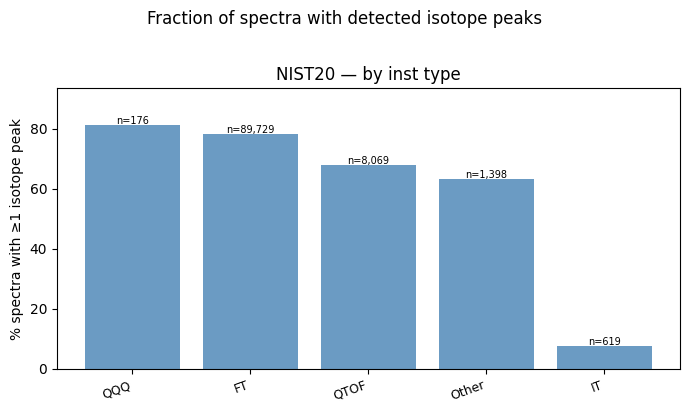

In [27]:
# ── Overview: % spectra with isotope peaks by inst_type ──────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
plot_bar_by_group(ax, stats20, "inst_type", "NIST20", color="steelblue")
plt.suptitle("Fraction of spectra with detected isotope peaks", y=1.02)
plt.tight_layout()
plt.show()

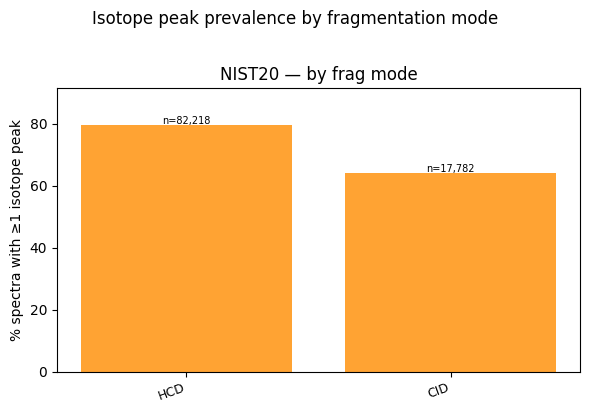

In [28]:
# ── By frag_mode ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))
plot_bar_by_group(ax, stats20, "frag_mode", "NIST20", color="darkorange")
plt.suptitle("Isotope peak prevalence by fragmentation mode", y=1.02)
plt.tight_layout()
plt.show()

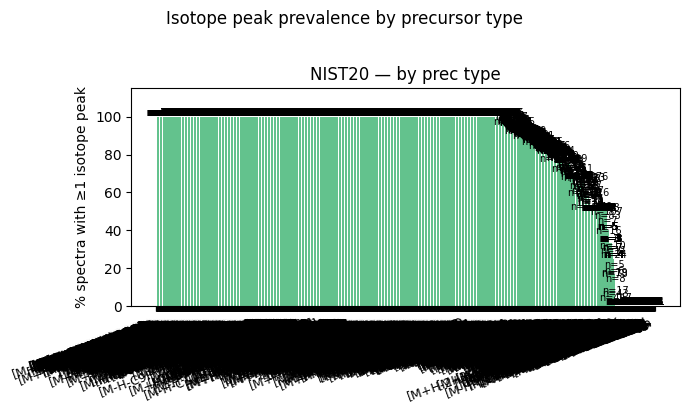

In [29]:
# ── By prec_type ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
plot_bar_by_group(ax, stats20, "prec_type", "NIST20", color="mediumseagreen")
plt.suptitle("Isotope peak prevalence by precursor type", y=1.02)
plt.tight_layout()
plt.show()

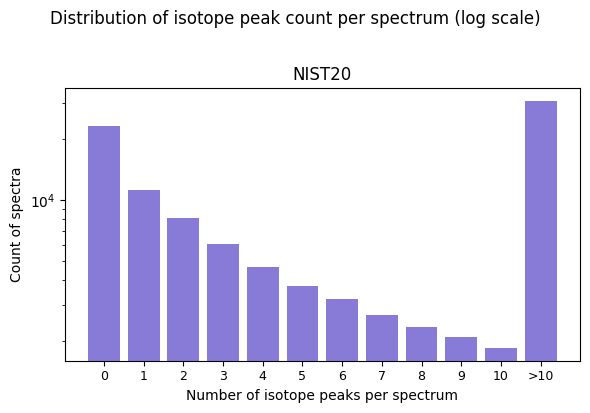

In [30]:
# ── Distribution: number of isotope peaks per spectrum ────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))

counts = stats20["n_isotope"].value_counts().sort_index()
# Show 0..10, group rest
MAX_SHOW = 10
low = counts[counts.index <= MAX_SHOW]
high_sum = counts[counts.index > MAX_SHOW].sum()
xs = list(low.index) + ([f">{MAX_SHOW}"] if high_sum > 0 else [])
ys = list(low.values) + ([high_sum] if high_sum > 0 else [])
ax.bar(range(len(xs)), ys, color="slateblue", alpha=0.8)
ax.set_xticks(range(len(xs)))
ax.set_xticklabels(xs, fontsize=9)
ax.set_xlabel("Number of isotope peaks per spectrum")
ax.set_ylabel("Count of spectra")
ax.set_title("NIST20")
ax.set_yscale("log")

plt.suptitle("Distribution of isotope peak count per spectrum (log scale)", y=1.02)
plt.tight_layout()
plt.show()

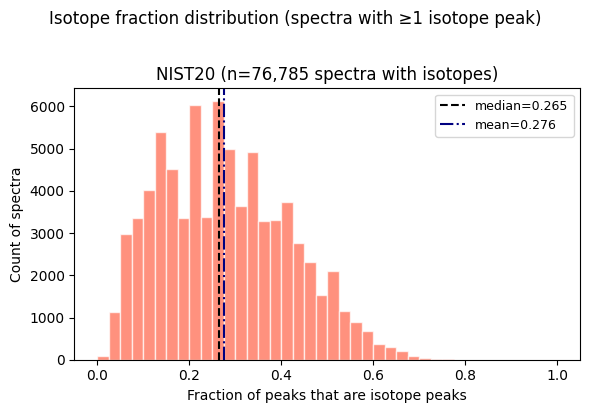

In [31]:
# ── Distribution: fraction of peaks that are isotope peaks ───────────────────
# Only for spectra that have ≥1 isotope peak
fig, ax = plt.subplots(figsize=(6, 4))

sub = stats20[stats20["has_isotope"] & stats20["frac_isotope"].notna()]["frac_isotope"]
ax.hist(sub, bins=40, range=(0, 1), color="tomato", alpha=0.7, edgecolor="white")
ax.axvline(sub.median(), color="black", lw=1.5, ls="--", label=f"median={sub.median():.3f}")
ax.axvline(sub.mean(), color="navy", lw=1.5, ls="-.", label=f"mean={sub.mean():.3f}")
ax.set_xlabel("Fraction of peaks that are isotope peaks")
ax.set_ylabel("Count of spectra")
ax.set_title(f"NIST20 (n={len(sub):,} spectra with isotopes)")
ax.legend(fontsize=9)

plt.suptitle("Isotope fraction distribution (spectra with ≥1 isotope peak)", y=1.02)
plt.tight_layout()
plt.show()

## Example spectra with isotope peaks highlighted

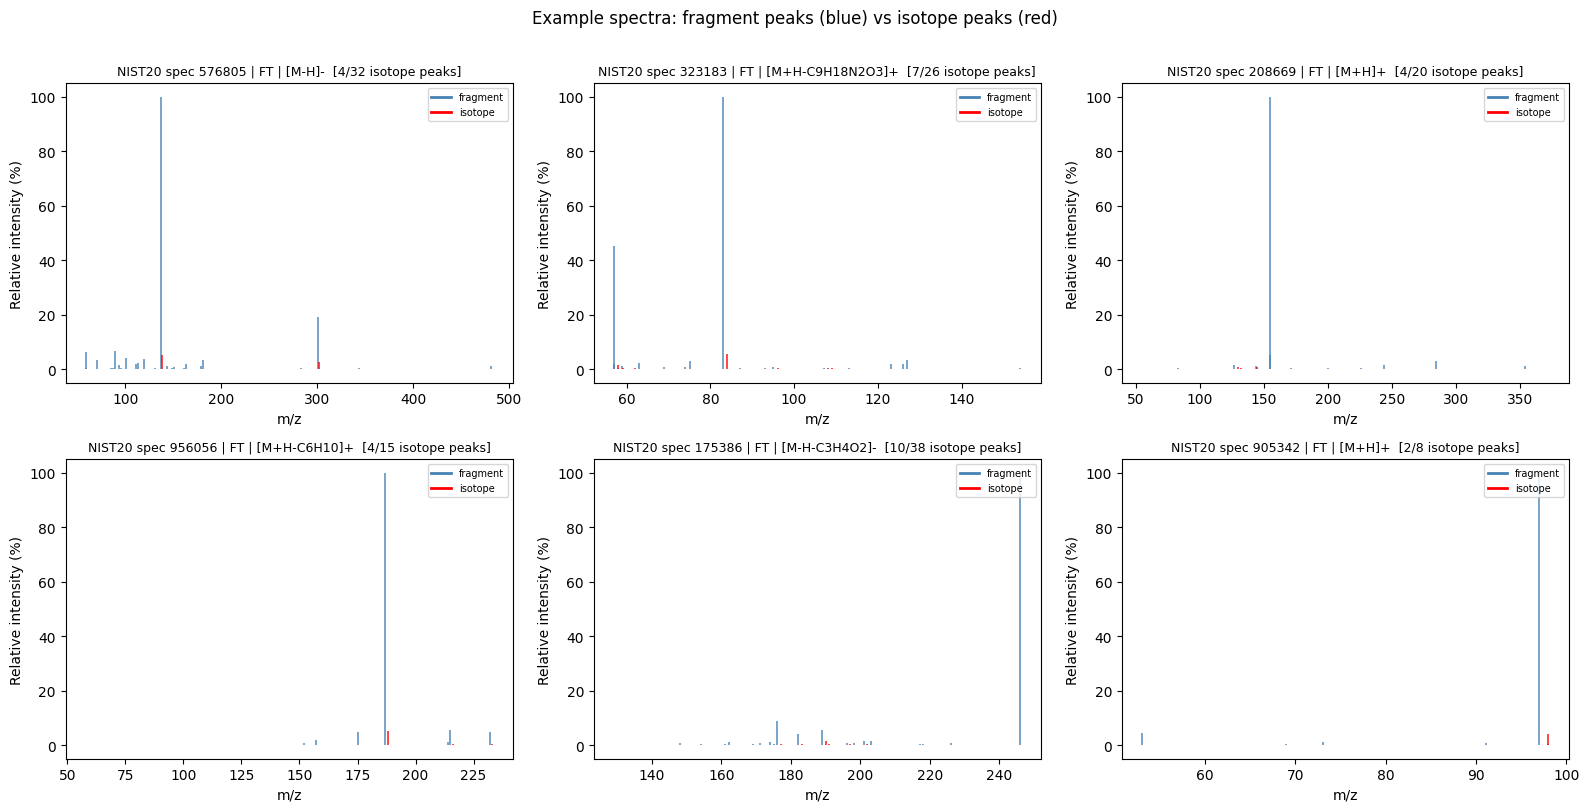

In [32]:
def plot_spectrum_with_isotopes(
    ax: plt.Axes,
    peaks: list,
    title: str = "",
    mz_tol: float = 0.02,
    max_isotope: int = 3,
) -> None:
    """Plot a spectrum with isotope peaks highlighted in red."""
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    ints_norm = ints / ints.max() * 100
    mask = detect_isotope_peaks(mzs, ints, mz_tol=mz_tol, max_isotope=max_isotope)

    for mz, intensity, is_iso in zip(mzs, ints_norm, mask):
        color = "red" if is_iso else "steelblue"
        ax.vlines(mz, 0, intensity, color=color, lw=1.2, alpha=0.85)

    n_iso = mask.sum()
    ax.set_xlabel("m/z")
    ax.set_ylabel("Relative intensity (%)")
    ax.set_title(f"{title}  [{n_iso}/{len(mzs)} isotope peaks]", fontsize=9)
    ax.legend(
        handles=[
            Line2D([0], [0], color="steelblue", lw=2, label="fragment"),
            Line2D([0], [0], color="red", lw=2, label="isotope"),
        ],
        fontsize=7,
    )


# Pull 6 spectra that have isotope peaks (from NIST20)
example_ids = stats20[stats20["n_isotope"] >= 2]["spec_id"].sample(6, random_state=0).values
ex_peaks = (
    spec20[spec20["spec_id"].isin(example_ids)][["spec_id", "peaks", "inst_type", "prec_type"]]
    .set_index("spec_id")
    .loc[example_ids]
)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (spec_id, row) in zip(axes.flat, ex_peaks.iterrows()):
    title = f"NIST20 spec {spec_id} | {row['inst_type']} | {row['prec_type']}"
    plot_spectrum_with_isotopes(ax, row["peaks"], title=title)
plt.suptitle("Example spectra: fragment peaks (blue) vs isotope peaks (red)", y=1.01)
plt.tight_layout()
plt.show()


## Sensitivity to `mz_tol` and `check_intensity`

In [33]:
# How sensitive are results to the tolerance and intensity-check flag?
# Use a small NIST20 sub-sample for speed.
SENS_N = 10_000
sens_sample = spec20.sample(SENS_N, random_state=0)

configs = [
    {"mz_tol": 0.01, "check_intensity": True},
    {"mz_tol": 0.02, "check_intensity": True},   # default
    {"mz_tol": 0.05, "check_intensity": True},
    {"mz_tol": 0.02, "check_intensity": False},
]

rows = []
for cfg in tqdm(configs, desc="Sensitivity configs"):
    pct = sens_sample["peaks"].apply(
        lambda p: compute_isotope_stats(p, **cfg)["has_isotope"]
    ).mean() * 100
    mean_n = sens_sample["peaks"].apply(
        lambda p: compute_isotope_stats(p, **cfg)["n_isotope"]
    ).mean()
    rows.append({**cfg, "pct_has_isotope": pct, "mean_n_isotope": mean_n})

sens_df = pd.DataFrame(rows)
print("Sensitivity analysis (NIST20 sample, n={:,}):".format(SENS_N))
display(sens_df.round(3))

Sensitivity configs:   0%|          | 0/4 [00:00<?, ?it/s]

Sensitivity analysis (NIST20 sample, n=10,000):


,mz_tol,check_intensity,pct_has_isotope,mean_n_isotope
0,0.01,True,73.48,15.351
1,0.02,True,76.06,19.712
2,0.05,True,79.75,27.160
3,0.02,False,83.45,31.088


## Peaks above precursor m/z as a precursor-isotope indicator

In MS/MS, all fragment peaks must be lighter than the precursor. Any peak at
`prec_mz + k × 1.003355 Da` is therefore **precursor isotope leakage** — the
instrument co-isolated an M+k isotopologue of the precursor. These are not
fragment peaks and should be filtered from training data.

This section checks:
- What fraction of spectra contain any peak above `prec_mz`?
- What fraction of those align to the expected isotope spacing (are true leakage)?
- How does this vary by instrument type?

Checking prec-iso peaks:   0%|          | 0/20000 [00:00<?, ?it/s]

Spectra with ≥1 peak above prec_mz:              26.98%
  …of which at isotope spacing (true leakage):   16.68%
  …above prec but NOT isotope spacing:           10.30%

By instrument type:
           % above prec  % prec isotope leakage
inst_type                                      
FT                27.04                   17.12
IT                 5.30                    1.52
Other             64.81                   28.24
QQQ               70.59                    2.94
QTOF              22.06                   11.70



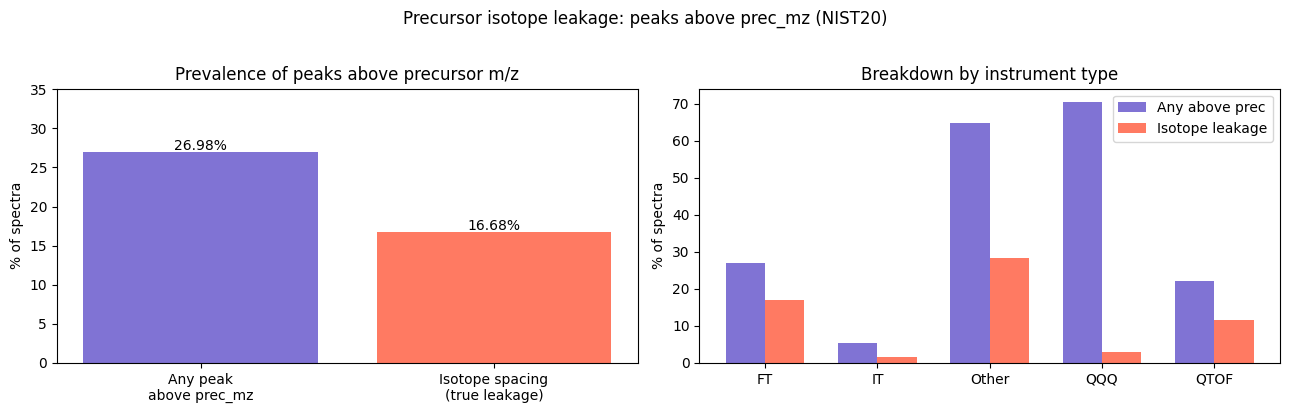


Spectra with peaks above prec_mz but NOT at isotope spacing: 2,060
  inst_type breakdown:
inst_type
FT       1790
QTOF      163
Other      79
QQQ        23
IT          5


In [34]:
PREC_ISO_N = 20_000
prec_sample = (
    spec20[spec20["prec_mz"].notna() & (spec20["prec_mz"] > 0)]
    .sample(min(PREC_ISO_N, len(spec20)), random_state=11)
    .reset_index(drop=True)
)


def check_prec_iso_peaks(row: pd.Series, mz_tol: float = 0.02, max_k: int = 3) -> dict:
    """Check for peaks above precursor m/z and whether they match isotope spacing."""
    peaks = row["peaks"]
    prec_mz = row["prec_mz"]
    if not peaks or not (prec_mz > 0):
        return {"n_above_prec": 0, "has_above_prec": False, "has_prec_iso": False}
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    above = mzs[mzs > prec_mz + mz_tol]
    matched_ks = [
        k for k in range(1, max_k + 1)
        if np.any(np.abs(above - (prec_mz + k * NEUTRON_MASS)) <= mz_tol)
    ]
    return {
        "n_above_prec": int(len(above)),
        "has_above_prec": len(above) > 0,
        "has_prec_iso": len(matched_ks) > 0,
    }


tqdm.pandas(desc="Checking prec-iso peaks")
prec_iso_stats = prec_sample.progress_apply(check_prec_iso_peaks, axis=1).apply(pd.Series)
prec_df = pd.concat(
    [prec_sample[["spec_id", "inst_type", "prec_mz", "prec_type"]], prec_iso_stats], axis=1
)

pct_above = 100 * prec_df["has_above_prec"].mean()
pct_prec_iso = 100 * prec_df["has_prec_iso"].mean()
n_above_only = (prec_df["has_above_prec"] & ~prec_df["has_prec_iso"]).sum()
print(f"Spectra with ≥1 peak above prec_mz:              {pct_above:.2f}%")
print(f"  …of which at isotope spacing (true leakage):   {pct_prec_iso:.2f}%")
print(f"  …above prec but NOT isotope spacing:           {100*n_above_only/len(prec_df):.2f}%")
print()

# Breakdown by instrument type
inst_tbl = (
    prec_df.groupby("inst_type")[["has_above_prec", "has_prec_iso"]]
    .mean()
    .mul(100)
    .rename(columns={"has_above_prec": "% above prec", "has_prec_iso": "% prec isotope leakage"})
    .round(2)
)
print("By instrument type:")
print(inst_tbl.to_string())
print()

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: overall bar — above prec vs isotope-matching
ax = axes[0]
labels = ["Any peak\nabove prec_mz", "Isotope spacing\n(true leakage)"]
vals = [pct_above, pct_prec_iso]
ax.bar(labels, vals, color=["slateblue", "tomato"], alpha=0.85)
for i, v in enumerate(vals):
    ax.text(i, v + 0.3, f"{v:.2f}%", ha="center", fontsize=10)
ax.set_ylabel("% of spectra")
ax.set_title("Prevalence of peaks above precursor m/z")
ax.set_ylim(0, max(vals) * 1.3)

# Right: by inst_type (grouped)
ax = axes[1]
inst_tbl_plot = inst_tbl.reset_index()
x = np.arange(len(inst_tbl_plot))
w = 0.35
ax.bar(x - w / 2, inst_tbl_plot["% above prec"], w, label="Any above prec", color="slateblue", alpha=0.85)
ax.bar(x + w / 2, inst_tbl_plot["% prec isotope leakage"], w, label="Isotope leakage", color="tomato", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(inst_tbl_plot["inst_type"])
ax.set_ylabel("% of spectra")
ax.set_title("Breakdown by instrument type")
ax.legend()

plt.suptitle("Precursor isotope leakage: peaks above prec_mz (NIST20)", y=1.02)
plt.tight_layout()
plt.show()

# What are the non-isotope-spaced peaks above prec_mz?
above_not_iso = prec_df[prec_df["has_above_prec"] & ~prec_df["has_prec_iso"]]
print(f"\nSpectra with peaks above prec_mz but NOT at isotope spacing: {len(above_not_iso):,}")
print("  inst_type breakdown:")
print(above_not_iso["inst_type"].value_counts().to_string())

### Precursor isotope leakage: formula + intensity validation

`check_prec_iso_peaks` (above) uses m/z spacing only.  Here we add two more signals:

1. **M+0 reference**: find the precursor ion peak in the spectrum (often present at
   low intensity as unfragmented ions).  `obs_ratio = I(M+k above prec) / I(M+0 prec)`.
2. **Formula-expected ratio**: `exp_ratio = expected_mk_ratio(formula, scale=1.0, k)`,
   using `prec_type` for adduct atoms (K, Cl, etc.).  True leakage should satisfy
   `0.3 × exp_ratio ≤ obs_ratio ≤ 3.0 × exp_ratio`.

Each above-prec candidate is classified:

| Label | Criterion |
|---|---|
| `confirmed` | m/z match **and** intensity ratio in window |
| `mz_bad_ratio` | m/z match but ratio outside window |
| `mz_no_m0` | m/z match but no M+0 prec peak found (can't check intensity) |
| `noise` | above prec, no m/z match at any k |

In [ ]:
MZ_TOL_PREC = 0.02
LO_RATIO, HI_RATIO = 0.3, 3.0


def check_prec_iso_extended(
    row: pd.Series,
    mz_tol: float = MZ_TOL_PREC,
    max_k: int = 3,
    lo: float = LO_RATIO,
    hi: float = HI_RATIO,
) -> dict:
    """Extended precursor isotope leakage check using m/z, formula, and intensity.

    Args:
        row: DataFrame row with 'peaks', 'prec_mz', 'formula', 'prec_type'.
        mz_tol: m/z tolerance in Da for matching peaks.
        max_k: Maximum isotope order to check.
        lo: Lower intensity-ratio multiplier relative to expected ratio.
        hi: Upper intensity-ratio multiplier relative to expected ratio.

    Returns:
        Dict with per-spectrum leakage classification counts and flags.
    """
    peaks = row["peaks"]
    prec_mz = float(row["prec_mz"]) if not pd.isna(row["prec_mz"]) else 0.0
    formula = row["formula"] if isinstance(row.get("formula"), str) else None
    prec_type = row["prec_type"] if isinstance(row.get("prec_type"), str) else None

    out = {
        "n_above_prec": 0,
        "has_above_prec": False,
        "has_prec_iso_mz": False,
        "has_confirmed": False,
        "n_confirmed": 0,
        "n_mz_bad_ratio": 0,
        "n_mz_no_m0": 0,
        "m0_found": False,
        "m0_int": np.nan,
    }

    if not peaks or prec_mz <= 0:
        return out

    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)

    # Peaks above precursor
    above_mask = mzs > prec_mz + mz_tol
    above_mzs = mzs[above_mask]
    above_ints = ints[above_mask]
    out["n_above_prec"] = int(len(above_mzs))
    out["has_above_prec"] = len(above_mzs) > 0

    if len(above_mzs) == 0:
        return out

    # Find M+0 reference: peak nearest to prec_mz within tolerance
    d_to_prec = np.abs(mzs - prec_mz)
    m0_idx = int(np.argmin(d_to_prec))
    m0_found = bool(d_to_prec[m0_idx] <= mz_tol)
    m0_int = float(ints[m0_idx]) if m0_found else np.nan
    out["m0_found"] = m0_found
    out["m0_int"] = m0_int

    confirmed = 0
    bad_ratio = 0
    no_m0 = 0
    any_mz = False

    for k in range(1, max_k + 1):
        target = prec_mz + k * NEUTRON_MASS
        cand_mask = np.abs(above_mzs - target) <= mz_tol
        if not cand_mask.any():
            continue
        any_mz = True

        if not m0_found or formula is None:
            no_m0 += 1
            continue

        best_int = above_ints[cand_mask].max()
        obs_ratio = best_int / m0_int
        exp_ratio = expected_mk_ratio(formula, scale=1.0, k=k, prec_type=prec_type)
        if lo * exp_ratio <= obs_ratio <= hi * exp_ratio:
            confirmed += 1
        else:
            bad_ratio += 1

    out["has_prec_iso_mz"] = any_mz
    out["has_confirmed"] = confirmed > 0
    out["n_confirmed"] = confirmed
    out["n_mz_bad_ratio"] = bad_ratio
    out["n_mz_no_m0"] = no_m0
    return out


# ── Run on prec_sample (already includes formula + prec_type from spec20) ─────
print(f"Running extended prec-iso check on {len(prec_sample):,} spectra…")
tqdm.pandas(desc="Extended prec-iso", leave=True)
_ext = prec_sample.progress_apply(check_prec_iso_extended, axis=1).apply(pd.Series)
prec_ext_df = pd.concat(
    [prec_sample[["spec_id", "inst_type", "prec_mz", "prec_type", "formula"]], _ext],
    axis=1,
)
del _ext

has_formula = prec_ext_df["formula"].notna()
has_m0 = prec_ext_df["m0_found"]
print(f"\nSpectra with formula:                {has_formula.sum():,} / {len(prec_ext_df):,} "
      f"({100 * has_formula.mean():.1f}%)")
print(f"Spectra where M+0 prec peak found:   {has_m0.sum():,} / {len(prec_ext_df):,} "
      f"({100 * has_m0.mean():.1f}%)")
print(f"\nAmong spectra with peaks above prec_mz "
      f"(n={prec_ext_df['has_above_prec'].sum():,}):")
sub = prec_ext_df[prec_ext_df["has_above_prec"]]
print(f"  m/z match only (any k):              "
      f"{sub['has_prec_iso_mz'].sum():,} ({100 * sub['has_prec_iso_mz'].mean():.1f}%)")
_can_check = sub[sub["m0_found"] & sub["formula"].notna() & sub["has_prec_iso_mz"]]
print(f"  m/z match + M+0 found + formula:     {len(_can_check):,}  (can apply intensity check)")
print(f"    → confirmed (ratio in window):     "
      f"{_can_check['has_confirmed'].sum():,} ({100 * _can_check['has_confirmed'].mean():.1f}%)")
print(f"    → m/z match but bad ratio:         "
      f"{_can_check['n_mz_bad_ratio'].gt(0).sum():,} "
      f"({100 * _can_check['n_mz_bad_ratio'].gt(0).mean():.1f}%)")

In [ ]:
# ── Collect per-peak obs/exp ratio for all m/z-matched above-prec candidates ──
# Used for scatter plot and histogram below.

peak_rows = []
for _, row in prec_ext_df[
    prec_ext_df["has_prec_iso_mz"]
    & prec_ext_df["m0_found"]
    & prec_ext_df["formula"].notna()
].iterrows():
    peaks = prec_sample.loc[prec_sample["spec_id"] == row["spec_id"], "peaks"]
    if peaks.empty:
        continue
    peaks = peaks.iloc[0]
    prec_mz = float(row["prec_mz"])
    formula = row["formula"]
    prec_type = row["prec_type"] if isinstance(row["prec_type"], str) else None
    inst_type = row["inst_type"]

    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)

    # M+0 intensity
    d0 = np.abs(mzs - prec_mz)
    m0_int = float(ints[int(np.argmin(d0))])
    if m0_int <= 0:
        continue

    above_mask = mzs > prec_mz + MZ_TOL_PREC
    above_mzs = mzs[above_mask]
    above_ints = ints[above_mask]

    for k in range(1, 4):
        target = prec_mz + k * NEUTRON_MASS
        cand = np.abs(above_mzs - target) <= MZ_TOL_PREC
        if not cand.any():
            continue
        best_int = float(above_ints[cand].max())
        obs_ratio = best_int / m0_int
        exp_ratio = expected_mk_ratio(formula, scale=1.0, k=k, prec_type=prec_type)
        confirmed = LO_RATIO * exp_ratio <= obs_ratio <= HI_RATIO * exp_ratio
        peak_rows.append({
            "inst_type": inst_type,
            "prec_type": prec_type,
            "k": k,
            "obs_ratio": obs_ratio,
            "exp_ratio": exp_ratio,
            "ratio_fold": obs_ratio / exp_ratio if exp_ratio > 0 else np.nan,
            "confirmed": confirmed,
        })

peak_detail_df = pd.DataFrame(peak_rows)
print(f"Per-peak records with obs+exp ratio: {len(peak_detail_df):,}")
print(f"  Confirmed (ratio in [{LO_RATIO}×, {HI_RATIO}×] window): "
      f"{peak_detail_df['confirmed'].sum():,} "
      f"({100 * peak_detail_df['confirmed'].mean():.1f}%)")
print(f"\nBy isotope order k:")
print(peak_detail_df.groupby("k")["confirmed"].agg(["sum", "count"])
      .assign(pct=lambda d: 100 * d["sum"] / d["count"])
      .rename(columns={"sum": "confirmed", "count": "total", "pct": "pct_confirmed"})
      .to_string())

In [ ]:
# ── Summary table: m/z-only vs confirmed by inst_type ─────────────────────────
rate_tbl = (
    prec_ext_df.groupby("inst_type")
    .agg(
        n_spectra=("spec_id", "count"),
        pct_above_prec=("has_above_prec", lambda x: 100 * x.mean()),
        pct_mz_match=("has_prec_iso_mz", lambda x: 100 * x.mean()),
        pct_confirmed=("has_confirmed", lambda x: 100 * x.mean()),
        pct_m0_found=("m0_found", lambda x: 100 * x.mean()),
    )
    .round(2)
    .reset_index()
)
print(rate_tbl.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Left: stacked bar — above / mz-match / confirmed rates per inst_type
ax = axes[0]
x = np.arange(len(rate_tbl))
w = 0.25
ax.bar(x - w, rate_tbl["pct_above_prec"], w, label="Any above prec",   color="slateblue", alpha=0.85)
ax.bar(x,     rate_tbl["pct_mz_match"],   w, label="m/z match (iso)",  color="darkorange", alpha=0.85)
ax.bar(x + w, rate_tbl["pct_confirmed"],  w, label="Confirmed (ratio)", color="tomato",     alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(rate_tbl["inst_type"])
ax.set_ylabel("% spectra")
ax.set_title("Precursor leakage rate by inst_type\n(m/z-only vs intensity-confirmed)")
ax.legend(fontsize=8)

# Middle: scatter obs_ratio vs exp_ratio, by inst_type, k=1 only
ax = axes[1]
k1 = peak_detail_df[peak_detail_df["k"] == 1]
for inst, color in [("FT", "steelblue"), ("QTOF", "darkorange"), ("IT", "mediumseagreen")]:
    sub = k1[k1["inst_type"] == inst]
    if len(sub) == 0:
        continue
    ax.scatter(sub["exp_ratio"], sub["obs_ratio"], s=8, alpha=0.4, label=inst, color=color)
lim = max(k1["exp_ratio"].max(), k1["obs_ratio"].clip(upper=5).max()) * 1.1
xs = np.linspace(0, lim, 100)
ax.plot(xs, xs, "k--", lw=1, label="obs = exp")
ax.fill_between(xs, LO_RATIO * xs, HI_RATIO * xs, alpha=0.08, color="green", label=f"[{LO_RATIO}×, {HI_RATIO}×] window")
ax.set_xlim(0, lim)
ax.set_ylim(0, min(k1["obs_ratio"].quantile(0.99) * 1.5, 10))
ax.set_xlabel("Expected M+1/M+0 ratio (formula-based)")
ax.set_ylabel("Observed M+1/M+0 ratio")
ax.set_title("k=1: observed vs expected ratio\n(above-prec peaks with M+0 found)")
ax.legend(fontsize=7, markerscale=2)

# Right: histogram of ratio_fold (obs/exp) — should be ~1 for true leakage
ax = axes[2]
for inst, color in [("FT", "steelblue"), ("QTOF", "darkorange"), ("IT", "mediumseagreen")]:
    sub = peak_detail_df[peak_detail_df["inst_type"] == inst]["ratio_fold"].dropna()
    if len(sub) < 5:
        continue
    ax.hist(sub.clip(0, 6), bins=60, range=(0, 6), alpha=0.5, color=color, label=inst, density=True)
ax.axvline(1.0, color="black", lw=1.5, ls="--", label="obs = exp")
ax.axvspan(LO_RATIO, HI_RATIO, alpha=0.10, color="green", label=f"[{LO_RATIO}×, {HI_RATIO}×]")
ax.set_xlabel("obs_ratio / exp_ratio (all k)")
ax.set_ylabel("Density")
ax.set_title("Ratio fold-change distribution\n(1.0 = perfect isotope prediction)")
ax.legend(fontsize=8)

plt.suptitle("Precursor leakage: formula + intensity validation (NIST20)", y=1.02)
plt.tight_layout()
plt.show()

### Isotopes co-occur at multiple peaks: sanity check by formula

**Key insight**: if a molecule contains Cl/Br, fragments that **retain the atom and carry the charge** will show an M+2 pattern. However, due to **charge migration fragmentation**, the charge can transfer to the complementary fragment (the one without Cl/Br), so many detected fragments from Cl/Br-containing precursors will *not* show M+2 — only those where charge and heavy atom end up on the same fragment.

As a result, `n_isotope` per spectrum should be *loosely* correlated with Cl/Br presence but will not scale linearly with atom count. Spectra of molecules with *no* Cl/Br/S can still show occasional isotope peaks (from ¹³C, ³⁴S, etc.), but should show far fewer than Cl/Br-containing molecules on average.

If the detection window is too loose, even molecules with *no* Cl/Br/S would
accumulate many accidental isotope matches — we'd "see them everywhere".

In [35]:
# ── Parse heavy-isotope atom counts from formula ─────────────────────────────
import re

_FORMULA_RE = re.compile(r'([A-Z][a-z]?)(\d*)')

def atom_counts(formula: str) -> dict[str, int]:
    """Return dict of element->count for a molecular formula string."""
    if not isinstance(formula, str):
        return {}
    return {el: (int(n) if n else 1) for el, n in _FORMULA_RE.findall(formula)}

# stats20 already contains 'formula' (run_isotope_analysis passes it through).
# If somehow missing, load from mol_df as fallback.
if 'formula' not in stats20.columns:
    _mol_f = pd.read_pickle(PROC_DP / 'nist20/mol_df.pkl')[['mol_id', 'formula']]
    stats_f = stats20.merge(_mol_f, on='mol_id', how='left')
    del _mol_f
else:
    stats_f = stats20.copy()

_atoms = stats_f['formula'].map(atom_counts)
stats_f['n_cl'] = _atoms.map(lambda d: d.get('Cl', 0))
stats_f['n_br'] = _atoms.map(lambda d: d.get('Br', 0))
stats_f['n_s']  = _atoms.map(lambda d: d.get('S',  0))
stats_f['has_clbr'] = (stats_f['n_cl'] + stats_f['n_br']) > 0
stats_f['has_s_only'] = (~stats_f['has_clbr']) & (stats_f['n_s'] > 0)
stats_f['group'] = np.where(
    stats_f['has_clbr'], 'Cl/Br',
    np.where(stats_f['has_s_only'], 'S only', 'Neither')
)

print('Formula group breakdown:')
print(stats_f['group'].value_counts())
print()
print(stats_f.groupby('group')[['n_isotope', 'frac_isotope']].agg(['mean', 'median']))

Formula group breakdown:
group
Neither    68342
Cl/Br      19321
S only     12337
Name: count, dtype: int64

         n_isotope        frac_isotope          
              mean median         mean    median
group                                           
Cl/Br    11.053620    4.0     0.224835  0.222222
Neither  29.151649    4.0     0.210133  0.200000
S only   10.467456    3.0     0.203701  0.187500


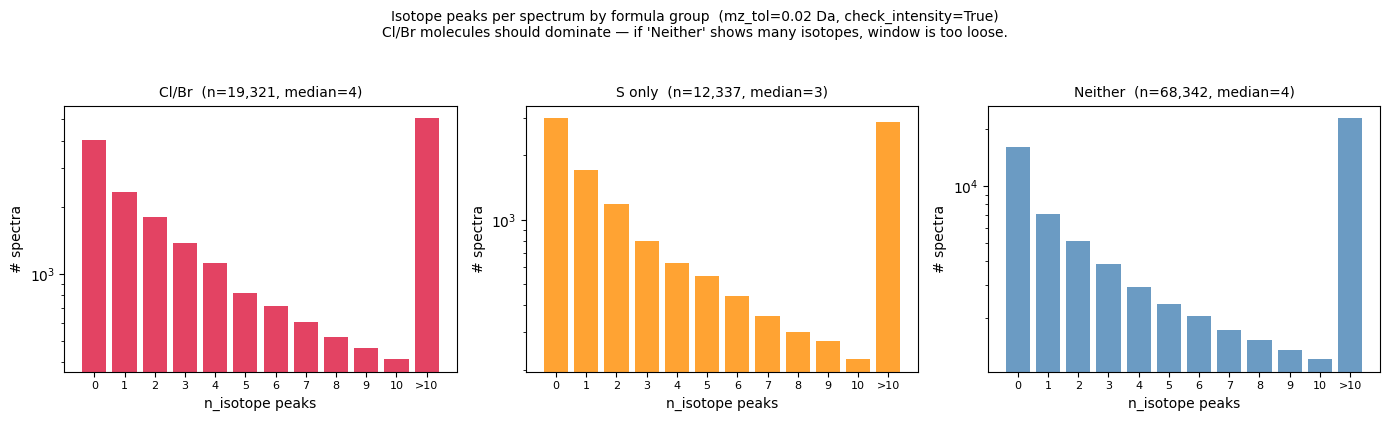

In [36]:
# ── n_isotope distribution by formula group ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)

GROUPS = ["Cl/Br", "S only", "Neither"]
COLORS = ["crimson", "darkorange", "steelblue"]

for ax, grp, color in zip(axes, GROUPS, COLORS):
    sub = stats_f[stats_f["group"] == grp]["n_isotope"]
    counts_g = sub.value_counts().sort_index()
    MAX_SHOW = 10
    low = counts_g[counts_g.index <= MAX_SHOW]
    high_sum = counts_g[counts_g.index > MAX_SHOW].sum()
    xs = list(low.index) + ([f">{MAX_SHOW}"] if high_sum > 0 else [])
    ys = list(low.values) + ([high_sum] if high_sum > 0 else [])
    ax.bar(range(len(xs)), ys, color=color, alpha=0.8)
    ax.set_xticks(range(len(xs)))
    ax.set_xticklabels(xs, fontsize=8)
    ax.set_xlabel("n_isotope peaks")
    ax.set_ylabel("# spectra")
    ax.set_yscale("log")
    n = len(sub)
    med = sub.median()
    ax.set_title(f"{grp}  (n={n:,}, median={med:.0f})", fontsize=10)

plt.suptitle(
    "Isotope peaks per spectrum by formula group  "
    "(mz_tol=0.02 Da, check_intensity=True)\n"
    "Cl/Br molecules should dominate — if 'Neither' shows many isotopes, window is too loose.",
    y=1.04, fontsize=10
)
plt.tight_layout()
plt.show()

mz_tol sweep:   0%|          | 0/5 [00:00<?, ?it/s]

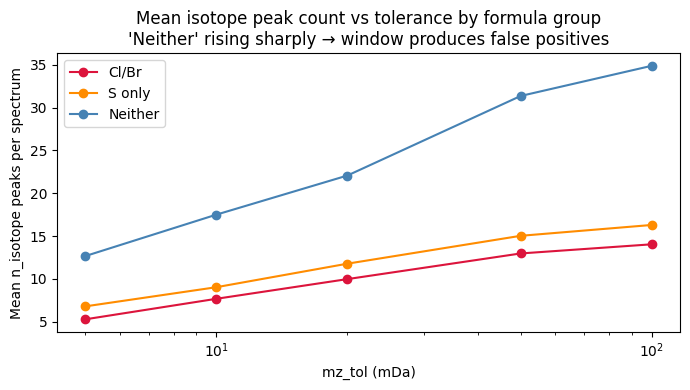

group   Cl/Br  Neither  S only
mz_tol                        
0.005    5.29    12.67    6.80
0.010    7.68    17.51    9.04
0.020    9.98    22.07   11.78
0.050   12.97    31.36   15.03
0.100   14.04    34.88   16.30


In [37]:
# ── mz_tol sweep: mean n_isotope for each formula group ─────────────────────
# If window is too loose, 'Neither' group's count should inflate sharply.
SWEEP_N = 5_000
sweep_sample = stats_f.sample(SWEEP_N, random_state=42).reset_index(drop=True)

# Get peaks via spec20 (merge on spec_id to avoid set_index fragility)
_peaks_map = spec20.set_index('spec_id')['peaks']
sweep_peaks = _peaks_map.reindex(sweep_sample['spec_id']).values

tolerances = [0.005, 0.010, 0.020, 0.050, 0.100]
sweep_rows = []
for tol in tqdm(tolerances, desc='mz_tol sweep'):
    n_iso = np.array([
        compute_isotope_stats(p, mz_tol=tol, check_intensity=True)['n_isotope']
        for p in sweep_peaks
    ])
    sweep_sample['n_iso_tmp'] = n_iso
    for grp in ['Cl/Br', 'S only', 'Neither']:
        mask = sweep_sample['group'] == grp
        sweep_rows.append({'mz_tol': tol, 'group': grp,
                           'mean_n_iso': sweep_sample.loc[mask, 'n_iso_tmp'].mean()})

sweep_df = pd.DataFrame(sweep_rows)

fig, ax = plt.subplots(figsize=(7, 4))
for grp, color in zip(['Cl/Br', 'S only', 'Neither'], ['crimson', 'darkorange', 'steelblue']):
    sub = sweep_df[sweep_df['group'] == grp]
    ax.plot(sub['mz_tol'] * 1000, sub['mean_n_iso'], marker='o', label=grp, color=color)

ax.set_xlabel('mz_tol (mDa)')
ax.set_ylabel('Mean n_isotope peaks per spectrum')
ax.set_title(
    'Mean isotope peak count vs tolerance by formula group\n'
    "'Neither' rising sharply → window produces false positives"
)
ax.legend()
ax.set_xscale('log')
plt.tight_layout()
plt.show()

print(sweep_df.pivot(index='mz_tol', columns='group', values='mean_n_iso').round(2))

## H-transfer vs Isotope: search-centre shift

FraGNNet's BFS fragmentation explicitly generates **H-transfer variants** (±1H, ±2H, … per fragment).
These are real signal the model must learn — but they sit close to M+1 isotope peaks.

**Relevant mass offsets from M+0:**

| Peak type | Mass offset | Note |
|---|---|---|
| M+1 isotope (¹³C) | +1.003355 Da | ¹³C – ¹²C monoisotopic spacing |
| H-gain fragment (+1H) | +1.007825 Da | hydrogen atom mass |
| **Separation (¹³C vs H-gain)** | **4.470 mDa** | — |
| `NEUTRON_MASS` (old search centre) | 1.008665 Da | 5.31 mDa off ¹³C → caused recall = 6.8% |

**Old approach** (`k × NEUTRON_MASS` as search centre, `mz_tol = 5 mDa`):
- Centre was 5.31 mDa away from true ¹³C M+0 → M+0 fell 0.31 mDa outside the window → missed every time
- H-gain M+0 only 0.84 mDa from centre → found first → dominated the isotope flags (FP)

**New approach** (`k × C13_SPACING` as search centre, `mz_tol = 4 mDa`):
- Centre lands exactly on ¹³C spacing → M+0 reliably found
- H-gain is 4.47 mDa from centre → outside 4 mDa window → excluded
- Safe filter threshold: `mz_tol = 0.004 Da` **for FT spectra only**
- For k ≥ 2: tolerance doubled (8 mDa) to cover ³⁷Cl / ⁴¹K / ³⁴S spacings (~1.997–1.999 Da)

With `mz_tol = 0.02 Da` (20 mDa) — naive detector — H-gain and isotope are **completely indistinguishable**.
Only **FT/Orbitrap** instruments (sub-ppm mass accuracy, ≈1 mDa at m/z 200) can separate them.

Neutron mass:        1.008665 Da
H atom mass:         1.007825 Da
Separation:          0.840 mDa

Mass accuracy needed to distinguish them:
  m/z  100: need < 8.40 ppm  (✓ FT/Orbitrap at typical 2-5 ppm accuracy)
  m/z  200: need < 4.20 ppm  (✓ FT/Orbitrap at typical 2-5 ppm accuracy)
  m/z  300: need < 2.80 ppm  (✓ FT/Orbitrap at typical 2-5 ppm accuracy)
  m/z  500: need < 1.68 ppm  (✓ FT/Orbitrap at typical 2-5 ppm accuracy)

FT spectra available in sample: 89,729 → using 5,000


FT offset scan:   0%|          | 0/5000 [00:00<?, ?it/s]

Detected 'isotope' pairs: 61,265


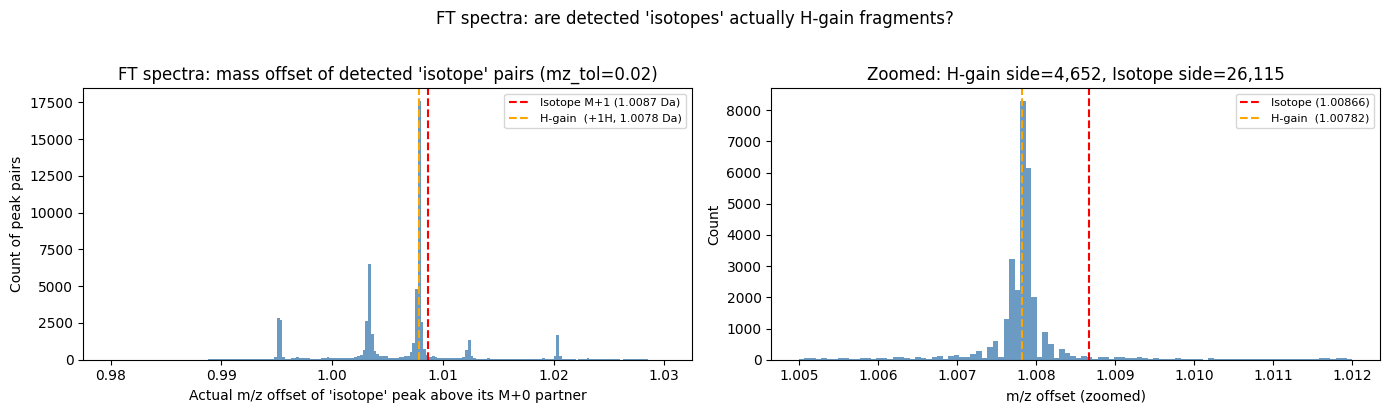


Of pairs in [1.005, 1.012] Da window:
  H-gain side  (<1.0077): 4,652  (15.1%)
  Isotope side (≥1.0077): 26,115  (84.9%)


In [38]:
H_ATOM_MASS = 1.007825   # H atom mass (H-gain fragment offset)
DELTA_MZ = NEUTRON_MASS - H_ATOM_MASS   # 0.000840 Da separation

print(f"Neutron mass:        {NEUTRON_MASS:.6f} Da")
print(f"H atom mass:         {H_ATOM_MASS:.6f} Da")
print(f"Separation:          {DELTA_MZ*1000:.3f} mDa")
print()
print("Mass accuracy needed to distinguish them:")
for mz in [100, 200, 300, 500]:
    ppm = DELTA_MZ / mz * 1e6
    print(f"  m/z {mz:4d}: need < {ppm:.2f} ppm  "
          f"({'✓ FT/Orbitrap' if ppm > 1 else '✗ requires ultra-high res'} at typical 2-5 ppm accuracy)")

# ── For FT spectra: measure the actual mass offset distribution ───────────────
ft_mask = spec20["inst_type"] == "FT"
ft_sub = spec20[ft_mask].sample(min(5_000, ft_mask.sum()), random_state=3).reset_index(drop=True)
print(f"\nFT spectra available in sample: {ft_mask.sum():,} → using {len(ft_sub):,}")

offsets = []
for _, row in tqdm(ft_sub.iterrows(), total=len(ft_sub), desc="FT offset scan"):
    peaks = row["peaks"]
    if not peaks:
        continue
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    mask = detect_isotope_peaks(mzs, ints, mz_tol=0.02)   # loose — catch everything
    si = np.argsort(mzs)
    smzs, sints, smask = mzs[si], ints[si], mask[si]
    for i in range(len(smzs)):
        if not smask[i]:
            continue
        target = smzs[i] - NEUTRON_MASS
        lo = np.searchsorted(smzs, target - 0.02, side="left")
        hi = np.searchsorted(smzs, target + 0.02, side="right")
        if lo >= hi:
            continue
        best = lo + int(np.argmin(np.abs(smzs[lo:hi] - target)))
        offsets.append(smzs[i] - smzs[best])

offsets = np.array(offsets)
print(f"Detected 'isotope' pairs: {len(offsets):,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: full distribution around NEUTRON_MASS
ax = axes[0]
ax.hist(offsets, bins=200, range=(0.98, 1.03), color="steelblue", alpha=0.8, edgecolor="none")
ax.axvline(NEUTRON_MASS, color="red",    lw=1.5, ls="--", label=f"Isotope M+1 ({NEUTRON_MASS:.4f} Da)")
ax.axvline(H_ATOM_MASS,  color="orange", lw=1.5, ls="--", label=f"H-gain  (+1H, {H_ATOM_MASS:.4f} Da)")
ax.set_xlabel("Actual m/z offset of 'isotope' peak above its M+0 partner")
ax.set_ylabel("Count of peak pairs")
ax.set_title("FT spectra: mass offset of detected 'isotope' pairs (mz_tol=0.02)")
ax.legend(fontsize=8)

# Right: zoom in to 0.84 mDa window to see bimodal split
ax = axes[1]
zoom_lo, zoom_hi = 1.005, 1.012
in_window = offsets[(offsets >= zoom_lo) & (offsets <= zoom_hi)]
ax.hist(in_window, bins=100, range=(zoom_lo, zoom_hi), color="steelblue", alpha=0.8, edgecolor="none")
ax.axvline(NEUTRON_MASS, color="red",    lw=1.5, ls="--", label=f"Isotope ({NEUTRON_MASS:.5f})")
ax.axvline(H_ATOM_MASS,  color="orange", lw=1.5, ls="--", label=f"H-gain  ({H_ATOM_MASS:.5f})")
n_isotope_side = (in_window >= NEUTRON_MASS - 0.001).sum()
n_hgain_side   = (in_window <  NEUTRON_MASS - 0.001).sum()
ax.set_xlabel("m/z offset (zoomed)")
ax.set_ylabel("Count")
ax.set_title(f"Zoomed: H-gain side={n_hgain_side:,}, Isotope side={n_isotope_side:,}")
ax.legend(fontsize=8)

plt.suptitle("FT spectra: are detected 'isotopes' actually H-gain fragments?", y=1.02)
plt.tight_layout()
plt.show()

pct_hgain = 100 * n_hgain_side / max(1, n_hgain_side + n_isotope_side)
print(f"\nOf pairs in [1.005, 1.012] Da window:")
print(f"  H-gain side  (<{NEUTRON_MASS-0.001:.4f}): {n_hgain_side:,}  ({pct_hgain:.1f}%)")
print(f"  Isotope side (≥{NEUTRON_MASS-0.001:.4f}): {n_isotope_side:,}  ({100-pct_hgain:.1f}%)")

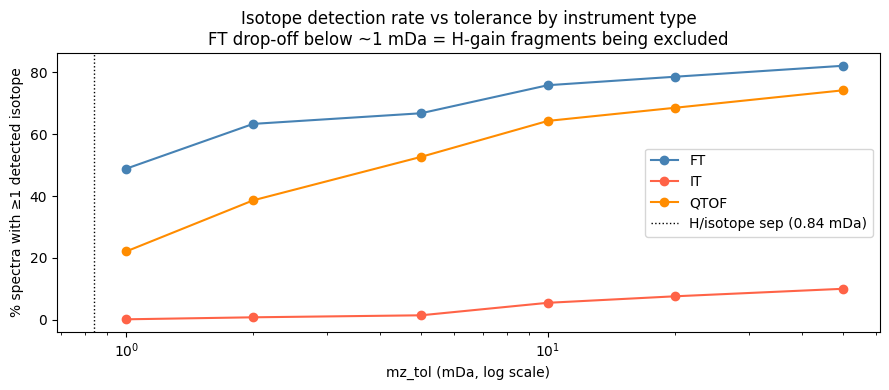

inst_type     FT     IT   QTOF
mz_tol                        
0.001      48.83   0.16  22.10
0.002      63.30   0.81  38.60
0.005      66.73   1.45  52.63
0.010      75.80   5.49  64.27
0.020      78.53   7.59  68.50
0.050      82.07  10.02  74.13


In [39]:
# ── Tolerance sweep: FT vs non-FT ────────────────────────────────────────────
# As mz_tol tightens below 0.84 mDa (0.001 Da), H-gain peaks should drop out
# for FT (resolved) but not for low-res instruments (never resolved).
tolerances = [0.001, 0.002, 0.005, 0.010, 0.020, 0.050]

inst_groups = {
    "FT":   spec20[spec20["inst_type"] == "FT"],
    "QTOF": spec20[spec20["inst_type"] == "QTOF"],
    "IT":   spec20[spec20["inst_type"] == "IT"],
}
# Sample each group
N_TOL = 3_000
tol_rows = []
for inst, grp in inst_groups.items():
    if len(grp) == 0:
        continue
    sub = grp.sample(min(N_TOL, len(grp)), random_state=5)
    for tol in tolerances:
        pct = sub["peaks"].apply(
            lambda p, t=tol: compute_isotope_stats(p, mz_tol=t)["has_isotope"]
        ).mean() * 100
        tol_rows.append({"inst_type": inst, "mz_tol": tol, "pct_has_isotope": pct})

tol_df = pd.DataFrame(tol_rows)

fig, ax = plt.subplots(figsize=(9, 4))
colors = {"FT": "steelblue", "QTOF": "darkorange", "IT": "tomato"}
for inst, grp in tol_df.groupby("inst_type"):
    ax.plot(grp["mz_tol"] * 1000, grp["pct_has_isotope"],
            marker="o", label=inst, color=colors.get(inst, "gray"))

ax.axvline(
    DELTA_MZ * 1000, color="black", lw=1, ls=":",
    label=f"H/isotope sep ({DELTA_MZ*1000:.2f} mDa)",
)
ax.set_xscale("log")
ax.set_xlabel("mz_tol (mDa, log scale)")
ax.set_ylabel("% spectra with ≥1 detected isotope")
ax.set_title(
    "Isotope detection rate vs tolerance by instrument type\n"
    "FT drop-off below ~1 mDa = H-gain fragments being excluded"
)
ax.legend()
plt.tight_layout()
plt.show()

# Print table
print(tol_df.pivot(index="mz_tol", columns="inst_type", values="pct_has_isotope").round(2).to_string())

## Formula-aware isotope detection

Because `formula` is available in `mol_df` for every spectrum, we can replace the naive
`M0_intensity ≥ M1_intensity` heuristic with a **quantitative intensity-ratio check**:

For a fragment peak at m/z `X` from precursor at m/z `P` with formula `F`:

```
scale      = X / P                  # fraction of molecule's mass in this fragment
exp_ratio  = M1(F) × scale          # expected M+1/M+0 ratio for this fragment
```

A peak is accepted as isotope only if `0.3 × exp_ratio ≤ obs_ratio ≤ 3.0 × exp_ratio`.

This **eliminates false positives** where two unrelated fragment peaks accidentally sit
~1 Da apart but have very different intensities (e.g. a 10% peak next to a 90% peak when
the formula predicts only a ~5% M+1).

In [40]:
# Run both detectors on a shared NIST20 sample (10k for speed)
FA_N = 10_000
fa_sample = spec20.sample(FA_N, random_state=7).reset_index(drop=True)

# Naive detection (default settings)
naive_stats = fa_sample["peaks"].apply(compute_isotope_stats).apply(pd.Series)

# Formula-aware detection — requires formula and prec_mz
has_formula = fa_sample["formula"].notna() & (fa_sample["prec_mz"].fillna(0) > 0)
print(f"Spectra with formula + prec_mz: {has_formula.sum():,} / {FA_N:,} "
      f"({100 * has_formula.mean():.1f}%)")

has_formula_vals = has_formula.to_numpy()
fa_stats = pd.DataFrame([
    compute_isotope_stats_formula_aware(
        row["peaks"], prec_mz=row["prec_mz"], formula=row["formula"]
    ) if has_formula_vals[i]
    else {"n_peaks": 0, "n_isotope_fa": np.nan, "frac_isotope_fa": np.nan, "has_isotope_fa": np.nan}
    for i, (_, row) in enumerate(fa_sample.iterrows())
])

# Combine
comparison = pd.concat([
    fa_sample[["spec_id", "inst_type", "formula", "prec_mz"]],
    naive_stats[["n_peaks", "n_isotope", "has_isotope"]],
    fa_stats[["n_isotope_fa", "has_isotope_fa"]],
], axis=1)

# Summary (only rows with valid formula-aware results)
valid = comparison[has_formula].copy()
naive_pct = 100 * valid["has_isotope"].mean()
fa_pct = 100 * valid["has_isotope_fa"].mean()

print(f"\nNaive detection:           {naive_pct:.2f}% spectra with ≥1 isotope peak")
print(f"Formula-aware detection:   {fa_pct:.2f}% spectra with ≥1 isotope peak")
print(f"Reduction:                 {naive_pct - fa_pct:.2f} pp  "
      f"({100 * (naive_pct - fa_pct) / naive_pct:.1f}% fewer detections)")

# False-positive candidates: naive says yes, formula-aware says no
fp_candidates = valid[valid["has_isotope"] & ~valid["has_isotope_fa"]]
# True positives: both agree
tp = valid[valid["has_isotope"] & valid["has_isotope_fa"]]
print(f"\nBoth agree (isotope):       {len(tp):,}")
print(f"Naive only (likely FP):     {len(fp_candidates):,}")
print(f"Formula-aware only (rare):  {(valid['has_isotope_fa'] & ~valid['has_isotope']).sum():,}")

/tmp/ipykernel_2442534/2981653565.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  has_formula = fa_sample["formula"].notna() & (fa_sample["prec_mz"].fillna(0) > 0)


Spectra with formula + prec_mz: 9,930 / 10,000 (99.3%)

Naive detection:           77.19% spectra with ≥1 isotope peak
Formula-aware detection:   59.59% spectra with ≥1 isotope peak
Reduction:                 17.60 pp  (22.8% fewer detections)

Both agree (isotope):       5,915
Naive only (likely FP):     7,665
Formula-aware only (rare):  2


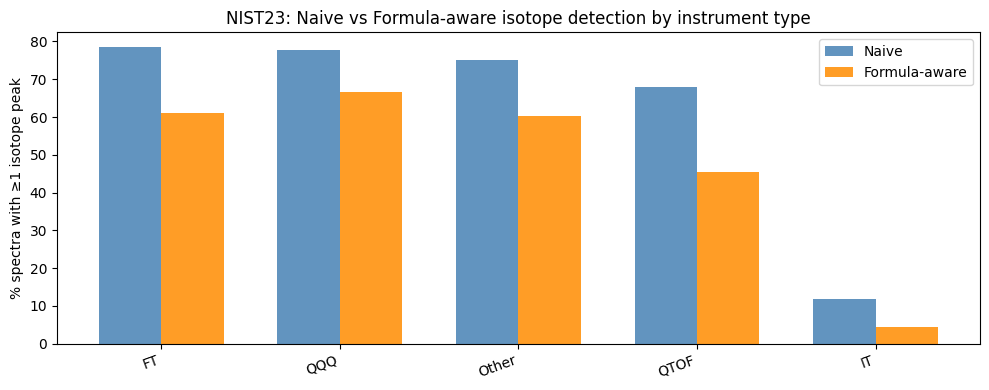

Ratio extraction:   0%|          | 0/2000 [00:00<?, ?it/s]

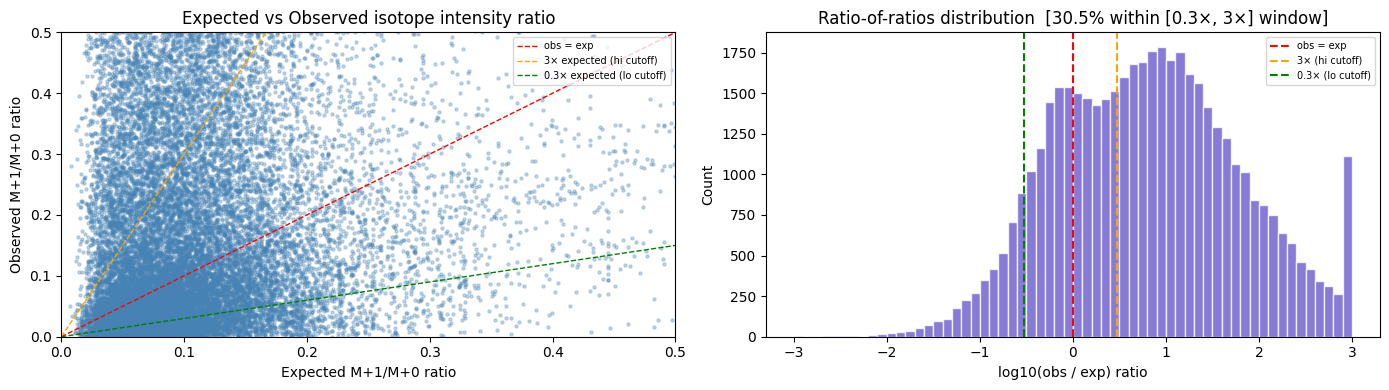


Of peaks naive-detected as isotopes: 30.5% pass the formula-aware ratio check


In [41]:
# ── Plot: naive vs formula-aware by instrument type ───────────────────────────
grp_naive = valid.groupby("inst_type")["has_isotope"].mean().mul(100).rename("Naive")
grp_fa = valid.groupby("inst_type")["has_isotope_fa"].mean().mul(100).rename("Formula-aware")
grp = pd.concat([grp_naive, grp_fa], axis=1).sort_values("Naive", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(grp))
w = 0.35
ax.bar(x - w / 2, grp["Naive"], w, label="Naive", color="steelblue", alpha=0.85)
ax.bar(x + w / 2, grp["Formula-aware"], w, label="Formula-aware", color="darkorange", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(grp.index, rotation=20, ha="right")
ax.set_ylabel("% spectra with ≥1 isotope peak")
ax.set_title("NIST23: Naive vs Formula-aware isotope detection by instrument type")
ax.legend()
plt.tight_layout()
plt.show()

# ── Distribution of observed M+1/M+0 ratios vs expected ──────────────────────
iso_rows = fa_sample[has_formula & naive_stats["has_isotope"].astype(bool)].head(2000)

obs_ratios, exp_ratios = [], []
for _, row in tqdm(iso_rows.iterrows(), total=len(iso_rows), desc="Ratio extraction"):
    mzs = np.array([p[0] for p in row["peaks"]], dtype=np.float64)
    ints = np.array([p[1] for p in row["peaks"]], dtype=np.float64)
    if len(mzs) == 0:
        continue
    mol_m1 = expected_m1_ratio(row["formula"])
    sort_idx = np.argsort(mzs)
    smzs, sints = mzs[sort_idx], ints[sort_idx]
    for i in range(len(smzs)):
        target = smzs[i] - NEUTRON_MASS
        lo = np.searchsorted(smzs, target - 0.02, side="left")
        hi = np.searchsorted(smzs, target + 0.02, side="right")
        if lo >= hi:
            continue
        m0 = sints[lo:hi].max()
        if m0 <= 0:
            continue
        obs = sints[i] / m0
        exp = max(mol_m1 * min(smzs[i] / row["prec_mz"], 1.0), 1e-4)
        obs_ratios.append(obs)
        exp_ratios.append(exp)

obs_ratios = np.array(obs_ratios)
exp_ratios = np.array(exp_ratios)
ratio_of_ratios = obs_ratios / exp_ratios  # 1.0 = perfect match

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].scatter(exp_ratios, obs_ratios, s=5, alpha=0.3, color="steelblue")
lim = max(exp_ratios.max(), obs_ratios.max()) * 1.05
axes[0].plot([0, lim], [0, lim], "r--", lw=1, label="obs = exp")
axes[0].plot([0, lim], [0, 3 * lim], "orange", lw=1, ls="--", label="3× expected (hi cutoff)")
axes[0].plot([0, lim], [0, 0.3 * lim], "green", lw=1, ls="--", label="0.3× expected (lo cutoff)")
axes[0].set_xlim(0, min(lim, 0.5))
axes[0].set_ylim(0, min(lim, 0.5))
axes[0].set_xlabel("Expected M+1/M+0 ratio")
axes[0].set_ylabel("Observed M+1/M+0 ratio")
axes[0].set_title("Expected vs Observed isotope intensity ratio")
axes[0].legend(fontsize=7)

axes[1].hist(np.log10(ratio_of_ratios.clip(1e-3, 1e3)), bins=60, color="slateblue", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", lw=1.5, ls="--", label="obs = exp")
axes[1].axvline(np.log10(3), color="orange", lw=1.5, ls="--", label="3× (hi cutoff)")
axes[1].axvline(np.log10(0.3), color="green", lw=1.5, ls="--", label="0.3× (lo cutoff)")
pct_in_window = 100 * np.mean((ratio_of_ratios >= 0.3) & (ratio_of_ratios <= 3.0))
axes[1].set_xlabel("log10(obs / exp) ratio")
axes[1].set_ylabel("Count")
axes[1].set_title(f"Ratio-of-ratios distribution  [{pct_in_window:.1f}% within [0.3×, 3×] window]")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

print(f"\nOf peaks naive-detected as isotopes: {pct_in_window:.1f}% pass the formula-aware ratio check")

## pyopenms-backed isotope detection

The existing formula-aware detector (cell above) uses:
- Fixed `k × NEUTRON_MASS` (1.008665 Da) for the peak spacing search
- Manually-coded `_M1_PER_ATOM` / `_M2_ADDITIVE_PER_ATOM` tables for the expected ratio

The new `detect_isotope_peaks_formula_aware` in `spec_utils.py` replaces both with pyopenms
`CoarseIsotopePatternGenerator`:
- **Exact isotopologue mass offsets** — e.g. Br M+2 is at 1.9970 Da, not 2 × 1.0087 = 2.0173 Da
- **Formula-predicted relative intensities** as the ratio gate (no mol_scale needed)

This section benchmarks it on the NIST20 sample and cross-references against NIST annotations.


In [42]:
from fragnnet.utils.formula_utils import parse_formula
from fragnnet.utils.isotope_utils import (
    detect_isotope_peaks_formula_aware as detect_iso_pyopenms,
)

# ── Run pyopenms detector on the same fa_sample used above ───────────────────
# fa_sample and has_formula/has_formula_vals are already defined in the cell above.

def _run_pyopenms(row) -> dict:
    """Apply pyopenms detector to one row; returns count/flag dict."""
    peaks = row["peaks"]
    formula = row["formula"]
    if not peaks or not isinstance(formula, str):
        return {"n_isotope_pom": np.nan, "has_isotope_pom": np.nan}
    try:
        ec = parse_formula(formula)
    except Exception:
        return {"n_isotope_pom": np.nan, "has_isotope_pom": np.nan}
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    mask = detect_iso_pyopenms(mzs, ints, ec, mz_tol=0.02, max_isotope=3)
    n_iso = int(mask.sum())
    return {"n_isotope_pom": n_iso, "has_isotope_pom": n_iso > 0}

print("Running pyopenms detector on fa_sample…")
pom_stats = pd.DataFrame(
    [_run_pyopenms(row) for _, row in tqdm(fa_sample.iterrows(), total=len(fa_sample))]
)

# ── Three-way comparison table ────────────────────────────────────────────────
comp3 = pd.concat([
    fa_sample[["spec_id", "inst_type", "formula", "prec_mz"]].reset_index(drop=True),
    naive_stats[["n_peaks", "n_isotope", "has_isotope"]].reset_index(drop=True),
    fa_stats[["n_isotope_fa", "has_isotope_fa"]].reset_index(drop=True),
    pom_stats.reset_index(drop=True),
], axis=1)

valid3 = comp3[has_formula].copy()

naive_pct  = 100 * valid3["has_isotope"].mean()
fa_pct     = 100 * valid3["has_isotope_fa"].mean()
pom_pct    = 100 * valid3["has_isotope_pom"].mean()

print(f"\n{'Detector':<30}  {'% spectra with ≥1 iso peak':>26}")
print("-" * 60)
print(f"{'Naive (NEUTRON_MASS step)':<30}  {naive_pct:>25.2f}%")
print(f"{'Formula-aware (manual tables)':<30}  {fa_pct:>25.2f}%")
print(f"{'pyopenms formula-aware':<30}  {pom_pct:>25.2f}%")

# Agreement matrix
both_naive_pom   = (valid3["has_isotope"] & valid3["has_isotope_pom"]).sum()
naive_only       = (valid3["has_isotope"] & ~valid3["has_isotope_pom"]).sum()
pom_only         = (~valid3["has_isotope"] & valid3["has_isotope_pom"]).sum()
neither          = (~valid3["has_isotope"] & ~valid3["has_isotope_pom"]).sum()

print(f"\nNaive ∩ pyopenms (both flag):     {both_naive_pom:,}")
print(f"Naive only (possible FP in naive): {naive_only:,}")
print(f"pyopenms only (missed by naive):   {pom_only:,}")
print(f"Neither flags:                     {neither:,}")


Running pyopenms detector on fa_sample…


  0%|          | 0/10000 [00:00<?, ?it/s]


Detector                        % spectra with ≥1 iso peak
------------------------------------------------------------
Naive (NEUTRON_MASS step)                           77.19%
Formula-aware (manual tables)                       59.59%
pyopenms formula-aware                              73.89%

Naive ∩ pyopenms (both flag):     7,198
Naive only (possible FP in naive): 467
pyopenms only (missed by naive):   139
Neither flags:                     2,126


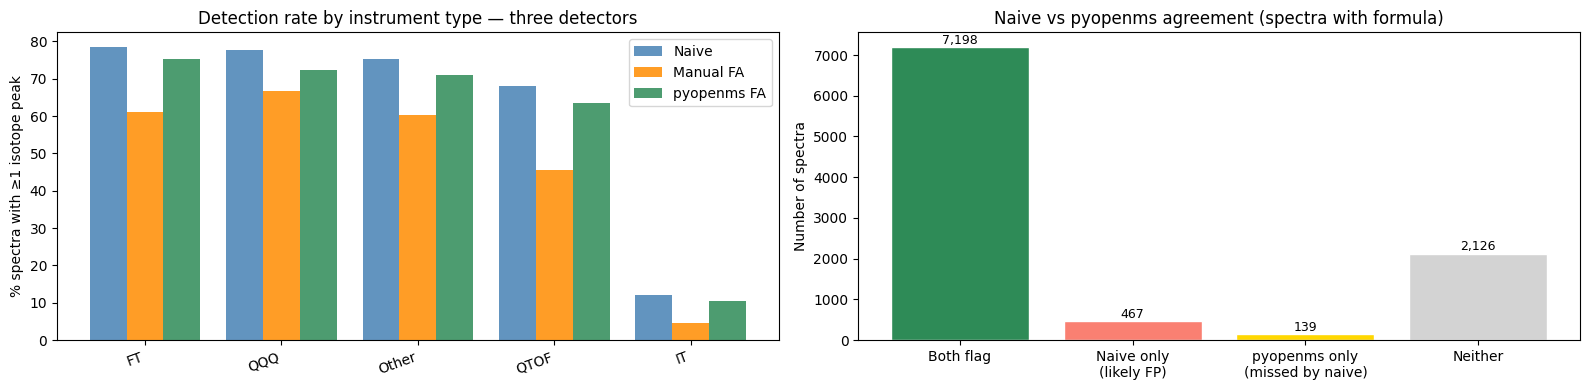

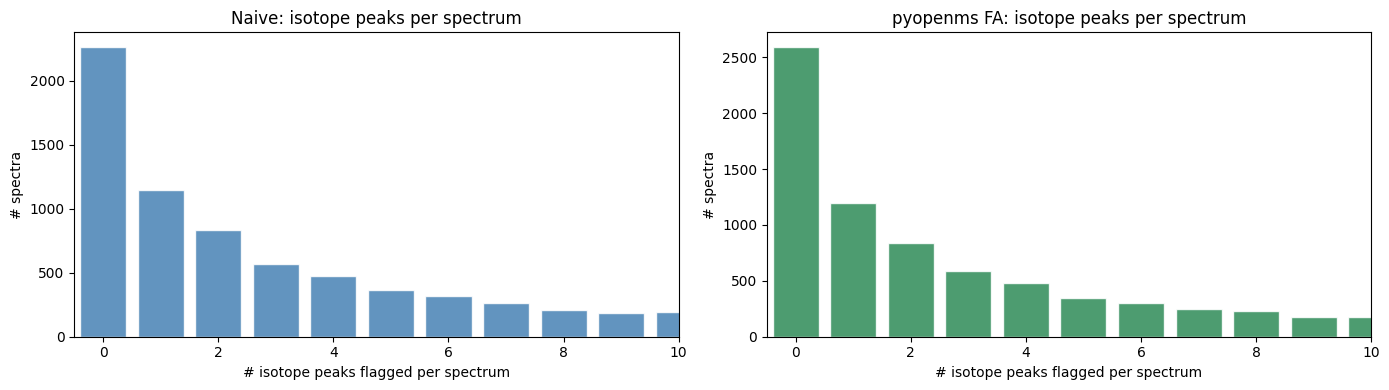

In [43]:
# ── Plot 1: detection rate by inst_type for all three detectors ──────────────
grp_naive3 = valid3.groupby("inst_type")["has_isotope"].mean().mul(100).rename("Naive")
grp_fa3    = valid3.groupby("inst_type")["has_isotope_fa"].mean().mul(100).rename("Manual FA")
grp_pom3   = valid3.groupby("inst_type")["has_isotope_pom"].mean().mul(100).rename("pyopenms FA")
grp3 = pd.concat([grp_naive3, grp_fa3, grp_pom3], axis=1).sort_values("Naive", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

x = np.arange(len(grp3))
w = 0.27
axes[0].bar(x - w, grp3["Naive"],      w, label="Naive",       color="steelblue",  alpha=0.85)
axes[0].bar(x,     grp3["Manual FA"],  w, label="Manual FA",   color="darkorange", alpha=0.85)
axes[0].bar(x + w, grp3["pyopenms FA"],w, label="pyopenms FA", color="seagreen",   alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(grp3.index, rotation=20, ha="right")
axes[0].set_ylabel("% spectra with ≥1 isotope peak")
axes[0].set_title("Detection rate by instrument type — three detectors")
axes[0].legend()

# ── Plot 2: Venn-style bar: agreement between naive and pyopenms ──────────────
cats   = ["Both flag", "Naive only\n(likely FP)", "pyopenms only\n(missed by naive)", "Neither"]
counts = [both_naive_pom, naive_only, pom_only, neither]
colors = ["seagreen", "salmon", "gold", "lightgrey"]
bars = axes[1].bar(cats, counts, color=colors, edgecolor="white")
for bar, cnt in zip(bars, counts):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                 f"{cnt:,}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylabel("Number of spectra")
axes[1].set_title("Naive vs pyopenms agreement (spectra with formula)")
plt.tight_layout()
plt.show()

# ── Plot 3: n_isotope per spectrum — naive vs pyopenms ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, label, color in [
    (axes[0], "n_isotope",     "Naive",       "steelblue"),
    (axes[1], "n_isotope_pom", "pyopenms FA", "seagreen"),
]:
    vals = valid3[col].dropna().astype(int)
    counts_arr = vals.value_counts().sort_index()
    ax.bar(counts_arr.index, counts_arr.values, color=color, alpha=0.85, edgecolor="white")
    ax.set_xlabel("# isotope peaks flagged per spectrum")
    ax.set_ylabel("# spectra")
    ax.set_title(f"{label}: isotope peaks per spectrum")
    ax.set_xlim(-0.5, min(counts_arr.index.max() + 1, 10))
plt.tight_layout()
plt.show()


In [46]:
# ── Precision / Recall vs NIST annotations ───────────────────────────────────
# Requires ann20 (loaded in "Cross-reference" section below).
# If ann20 is already loaded, skip the reload.
try:
    ann20  # noqa: F821
    print("ann20 already loaded.")
except NameError:
    print("Loading NIST20 ann_df…")
    ann20 = pd.read_pickle(PROC_DP / "nist20/ann_df.pkl")
    print(f"  ann_df shape: {ann20.shape}")

# Keep only isotope-annotated peaks; restrict to fa_sample spec_ids
ISO_TYPES = {"isotope", "isotope_peak", "iso"}
ann_iso = (
    ann20[ann20["spec_id"].isin(fa_sample["spec_id"])]
    .explode("ann_peak_mzs")
    .rename(columns={"ann_peak_mzs": "ann_mz"})
    .assign(ann_mz=lambda d: pd.to_numeric(d["ann_mz"], errors="coerce"))
    .dropna(subset=["ann_mz"])
    .reset_index(drop=True)
)
print(f"Annotated isotope peaks in fa_sample: {len(ann_iso):,}")

MZ_TOL_MATCH = 0.015  # 15 mDa to match a detected peak to an annotated one

def pr_vs_annotations(
    sample_df: pd.DataFrame,
    detected_col: str,
    label: str,
) -> dict:
    """Compute precision/recall of a detection column vs NIST annotation."""
    tp = fp = fn = 0
    for sid, grp in ann_iso.groupby("spec_id"):
        row = sample_df[sample_df["spec_id"] == sid]
        if row.empty:
            fn += len(grp)
            continue
        row = row.iloc[0]
        peaks = row["peaks"]
        formula = row.get("formula", None)
        if not peaks:
            fn += len(grp)
            continue
        mzs = np.array([p[0] for p in peaks], dtype=np.float64)
        ints = np.array([p[1] for p in peaks], dtype=np.float64)

        # Retrieve the detection mask for this row from comp3
        comp_row = comp3[comp3["spec_id"] == sid]
        if comp_row.empty or pd.isna(comp_row.iloc[0].get(detected_col, np.nan)):
            fn += len(grp)
            continue

        if detected_col == "n_isotope_pom":
            # Re-run to get the per-peak mask
            try:
                ec = parse_formula(formula)
                det_mask = detect_iso_pyopenms(mzs, ints, ec, mz_tol=0.02, max_isotope=3)
            except Exception:
                fn += len(grp)
                continue
        elif detected_col == "n_isotope":
            det_mask = detect_isotope_peaks(mzs, ints, mz_tol=0.02, max_isotope=3)
        else:
            fn += len(grp)
            continue

        det_mzs = mzs[det_mask]

        # Match each annotated peak to a detected peak
        for ann_mz in grp["ann_mz"].values:
            matched = np.any(np.abs(det_mzs - ann_mz) <= MZ_TOL_MATCH)
            if matched:
                tp += 1
            else:
                fn += 1

        # False positives: detected peaks not matching any annotation
        ann_mzs = grp["ann_mz"].values
        for det_mz in det_mzs:
            if not np.any(np.abs(ann_mzs - det_mz) <= MZ_TOL_MATCH):
                fp += 1

    prec = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    rec  = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else np.nan
    print(f"{label:<30}  TP={tp:,}  FP={fp:,}  FN={fn:,}  "
          f"Prec={prec:.3f}  Rec={rec:.3f}  F1={f1:.3f}")
    return {"label": label, "tp": tp, "fp": fp, "fn": fn,
            "precision": prec, "recall": rec, "f1": f1}

if len(ann_iso) > 0:
    print(f"\n{'Detector':<30}  {'TP':>6}  {'FP':>6}  {'FN':>6}  "
          f"{'Prec':>6}  {'Rec':>6}  {'F1':>6}")
    print("-" * 90)
    results = [
        pr_vs_annotations(fa_sample, "n_isotope",    "Naive"),
        pr_vs_annotations(fa_sample, "n_isotope_pom","pyopenms FA"),
    ]

    # Plot precision / recall / F1 side by side
    metrics_df = pd.DataFrame(results).set_index("label")
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(metrics_df))
    w = 0.25
    ax.bar(x - w, metrics_df["precision"], w, label="Precision", color="steelblue",  alpha=0.85)
    ax.bar(x,     metrics_df["recall"],    w, label="Recall",    color="darkorange", alpha=0.85)
    ax.bar(x + w, metrics_df["f1"],        w, label="F1",        color="seagreen",   alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_df.index)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.set_title("Isotope detection: Precision / Recall / F1 vs NIST annotations")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No annotated isotope peaks found in fa_sample — skipping precision/recall.")


ann20 already loaded.
Annotated isotope peaks in fa_sample: 3,512

Detector                            TP      FP      FN    Prec     Rec      F1
------------------------------------------------------------------------------------------


KeyError: 'ann_mz'

In [ ]:
# ── Br / Cl breakdown: where pyopenms offsets matter most ────────────────────
# Group formulas by whether they contain Br/Cl (heavy even-isotope elements
# where the fixed NEUTRON_MASS step drifts from the true M+2 position).

import re as _re

def has_heavy_isotope_element(formula: str) -> bool:
    """True if formula contains Cl or Br (significant even-mass isotopes)."""
    if not isinstance(formula, str):
        return False
    return bool(_re.search(r"Cl|Br", formula))

valid3["has_heavy"] = valid3["formula"].apply(has_heavy_isotope_element)

for group_label, mask in [("All", slice(None)), ("Has Cl/Br", valid3["has_heavy"]), ("No Cl/Br", ~valid3["has_heavy"])]:
    sub = valid3[mask] if isinstance(mask, pd.Series) else valid3
    n = len(sub)
    if n == 0:
        continue
    naive_r = 100 * sub["has_isotope"].mean()
    pom_r   = 100 * sub["has_isotope_pom"].mean()
    delta   = pom_r - naive_r
    print(f"{group_label:<12}  n={n:,}  naive={naive_r:.1f}%  pyopenms={pom_r:.1f}%  Δ={delta:+.1f} pp")

# ── n_isotope scatter: naive vs pyopenms per spectrum ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, heavy, title in [
    (axes[0], False, "No Cl/Br"),
    (axes[1], True,  "Has Cl/Br"),
]:
    sub = valid3[valid3["has_heavy"] == heavy]
    x = sub["n_isotope"].fillna(0).astype(int)
    y = sub["n_isotope_pom"].fillna(0).astype(int)
    # 2D histogram
    lim = max(x.max(), y.max(), 1) + 1
    h, xedge, yedge = np.histogram2d(x, y, bins=range(lim + 1))
    im = ax.imshow(h.T, origin="lower", aspect="auto", cmap="Blues",
                   extent=[xedge[0], xedge[-1], yedge[0], yedge[-1]])
    ax.plot([0, lim], [0, lim], "r--", lw=1, label="equal")
    ax.set_xlabel("Naive: n_isotope per spectrum")
    ax.set_ylabel("pyopenms: n_isotope per spectrum")
    ax.set_title(f"{title} (n={len(sub):,})")
    ax.legend(fontsize=8)
    plt.colorbar(im, ax=ax, label="# spectra")
plt.suptitle("Naive vs pyopenms: isotope peak count per spectrum", y=1.02)
plt.tight_layout()
plt.show()


## Cross-reference: NIST annotations vs m/z-spacing detector

`ann_df.ann_isotopes` contains NIST's own per-peak isotope labels (integer k: 0 = monoisotopic,
k > 0 = M+k) parsed from the annotation string (e.g. `C6H5+i`).  These are only available
for `nist20_hr` spectra with `[M+H]+` or `[M-H]-` precursors.

We join `ann_df` back to `spec_df` and ask:
- **Recall**: what fraction of NIST-labelled isotope peaks does the m/z detector find?
- **Precision**: what fraction of detector-flagged peaks are NIST-labelled isotopes?
- **Coverage gap**: how many spectra flagged by the detector have *no* annotation at all?

In [ ]:
print("Loading NIST20 ann_df…")
# Load all columns needed by both the cross-reference and DAG sections upfront
ann20 = pd.read_pickle(PROC_DP / "nist20/ann_df.pkl")[
    ["spec_id", "ann_peak_mzs", "ann_products", "ann_isotopes", "ann_exact_mzs"]
].copy()
ann_spec_ids = set(ann20["spec_id"].unique())
print(f"  Annotated spectra: {len(ann_spec_ids):,}")

# Load only peaks for annotated spec_ids — avoids keeping the full spec_df in memory
print("  Loading peaks for annotated spectra only…")
_tmp = pd.read_pickle(PROC_DP / "nist20/spec_df.pkl")[["spec_id", "peaks"]]
ann_peaks_dict: dict = (
    _tmp[_tmp["spec_id"].isin(ann_spec_ids)]
    .set_index("spec_id")["peaks"]
    .to_dict()
)
del _tmp; gc.collect()
print(f"  Loaded peaks for {len(ann_peaks_dict):,} annotated spectra")

# Explode for per-peak counts only (keep small, free after)
ann20_peaks = ann20.explode(["ann_peak_mzs", "ann_isotopes"]).rename(
    columns={"ann_peak_mzs": "ann_mz", "ann_isotopes": "ann_iso_k"}
)
ann20_peaks["ann_iso_k"] = pd.to_numeric(ann20_peaks["ann_iso_k"], errors="coerce").fillna(0).astype(int)
ann20_peaks["is_ann_isotope"] = ann20_peaks["ann_iso_k"] != 0

n_ann_iso = ann20_peaks["is_ann_isotope"].sum()
n_ann_total = len(ann20_peaks)
print(f"  Total annotated peaks: {n_ann_total:,}")
print(f"  NIST-labelled isotope peaks: {n_ann_iso:,} ({100*n_ann_iso/n_ann_total:.2f}%)")
print(f"  Spectra with ≥1 annotated isotope peak: "
      f"{ann20_peaks[ann20_peaks['is_ann_isotope']]['spec_id'].nunique():,}")
del ann20_peaks; gc.collect()


Loading NIST20 ann_df…


  Annotated spectra: 397,057
  Loading peaks for annotated spectra only…


  Loaded peaks for 397,057 annotated spectra


  Total annotated peaks: 15,530,287
  NIST-labelled isotope peaks: 621,005 (4.00%)
  Spectra with ≥1 annotated isotope peak: 120,393


0

In [ ]:
MZ_MATCH_TOL = 0.01  # 10 mDa for matching annotated peaks to detected peaks

# ── Step 1: precompute detection masks for all annotated spectra ──────────────
print(f"Precomputing detection masks for {len(ann_peaks_dict):,} spectra…")
det_dict: dict = {}   # spec_id -> (sorted_mzs, sorted_det_mask)
for spec_id, peaks in tqdm(ann_peaks_dict.items(), desc="Detection masks"):
    if not peaks:
        continue
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    mask = detect_isotope_peaks(mzs, ints)
    si = np.argsort(mzs)
    det_dict[spec_id] = (mzs[si], mask[si])
del ann_peaks_dict; gc.collect()
print(f"  Done. {len(det_dict):,} spectra with peaks.")

# ── Step 2: explode annotations → one row per annotated peak ─────────────────
ann20_exp = (
    ann20.explode(["ann_peak_mzs", "ann_isotopes"])
    .rename(columns={"ann_peak_mzs": "ann_mz", "ann_isotopes": "ann_iso_k"})
    .assign(ann_mz=lambda d: d["ann_mz"].astype(float),
            ann_iso_k=lambda d: pd.to_numeric(d["ann_iso_k"], errors="coerce").fillna(0).astype(int))
    [lambda d: d["spec_id"].isin(det_dict)]
    .reset_index(drop=True)
)
print(f"  Annotated peaks to match: {len(ann20_exp):,}")

# ── Step 3: vectorised nearest-neighbour match per spectrum ───────────────────
parts = []
for spec_id, grp in tqdm(ann20_exp.groupby("spec_id", sort=False),
                          desc="Matching peaks", total=ann20_exp["spec_id"].nunique()):
    smzs, smask = det_dict[spec_id]           # sorted mzs + detection mask
    amzs = grp["ann_mz"].to_numpy()

    idx = np.searchsorted(smzs, amzs).clip(0, len(smzs) - 1)
    idx_lo = (idx - 1).clip(0, len(smzs) - 1)
    d_hi = np.abs(smzs[idx]    - amzs)
    d_lo = np.abs(smzs[idx_lo] - amzs)
    best = np.where(d_lo < d_hi, idx_lo, idx)
    best_d = np.minimum(d_hi, d_lo)

    valid = best_d <= MZ_MATCH_TOL
    if not valid.any():
        continue
    sub = grp[valid].copy()
    sub["det_isotope"] = smask[best[valid]]
    parts.append(sub[["spec_id", "ann_mz", "ann_iso_k", "det_isotope"]])

xref_df = pd.concat(parts, ignore_index=True)
xref_df["is_ann_isotope"] = xref_df["ann_iso_k"] != 0
del ann20_exp, parts; gc.collect()

print(f"Matched {len(xref_df):,} annotated peaks")
print(f"  NIST isotope labels: {xref_df['is_ann_isotope'].sum():,}")
print(f"  Detector flags:      {xref_df['det_isotope'].sum():,}")


Precomputing detection masks for 397,057 spectra…


Detection masks:   0%|          | 0/397057 [00:00<?, ?it/s]

  Done. 397,057 spectra with peaks.


  Annotated peaks to match: 15,530,287


Matching peaks:   0%|          | 0/397057 [00:00<?, ?it/s]

Matched 15,530,287 annotated peaks
  NIST isotope labels: 621,005
  Detector flags:      5,163,101


In [ ]:
# ── Confusion matrix & metrics ────────────────────────────────────────────────
tp = ((xref_df["is_ann_isotope"]) & (xref_df["det_isotope"])).sum()
fp = ((~xref_df["is_ann_isotope"]) & (xref_df["det_isotope"])).sum()
fn = ((xref_df["is_ann_isotope"]) & (~xref_df["det_isotope"])).sum()
tn = ((~xref_df["is_ann_isotope"]) & (~xref_df["det_isotope"])).sum()

precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print("Confusion matrix (NIST annotation as ground truth):")
print(f"                   Det=isotope  Det=fragment")
print(f"  Ann=isotope  TP={tp:>8,}  FN={fn:>8,}   (NIST says isotope)")
print(f"  Ann=fragment FP={fp:>8,}  TN={tn:>8,}   (NIST says fragment)")
print()
print(f"Precision (of detector):  {precision:.3f}  — when detector fires, how often is NIST also isotope?")
print(f"Recall    (of detector):  {recall:.3f}  — what fraction of NIST isotopes does detector catch?")
print(f"F1:                       {f1:.3f}")
print()
print("Missed (FN) by isotope order k:")
print(xref_df[xref_df["is_ann_isotope"] & ~xref_df["det_isotope"]]["ann_iso_k"].value_counts().sort_index().to_string())

# ── Coverage gap ──────────────────────────────────────────────────────────────
# NOTE: det_iso_spec_ids comes from stats20 which is a 100k SAMPLE of NIST20,
# not the full dataset.  The gap counts are proportional, not absolute.
# NOTE: NIST annotations (ann_df) only cover nist20_hr spectra — LR spectra
# are never annotated by design, so they always appear in the "no annotation" bucket.
print()
det_iso_spec_ids = set(stats20[stats20["has_isotope"]]["spec_id"].dropna())
no_ann_but_detected = det_iso_spec_ids - ann_spec_ids
has_ann_and_detected = det_iso_spec_ids & ann_spec_ids
print(f"Spectra with detector isotopes (from {SAMPLE_N:,}-sample): {len(det_iso_spec_ids):,}")
print(f"  …that also have HR annotations:   {len(has_ann_and_detected):,} ({100*len(has_ann_and_detected)/max(1,len(det_iso_spec_ids)):.1f}%)")
print(f"  …with no HR annotation (LR/gap):  {len(no_ann_but_detected):,} ({100*len(no_ann_but_detected)/max(1,len(det_iso_spec_ids)):.1f}%)")

Confusion matrix (NIST annotation as ground truth):
                   Det=isotope  Det=fragment
  Ann=isotope  TP= 611,358  FN=   9,647   (NIST says isotope)
  Ann=fragment FP=4,551,743  TN=10,357,539   (NIST says fragment)

Precision (of detector):  0.118  — when detector fires, how often is NIST also isotope?
Recall    (of detector):  0.984  — what fraction of NIST isotopes does detector catch?
F1:                       0.211

Missed (FN) by isotope order k:
ann_iso_k
-1     435
 1    9047
 2     158
 3       7

Spectra with detector isotopes (from 100,000-sample): 76,785
  …that also have HR annotations:   26,058 (33.9%)
  …with no HR annotation (LR/gap):  50,727 (66.1%)


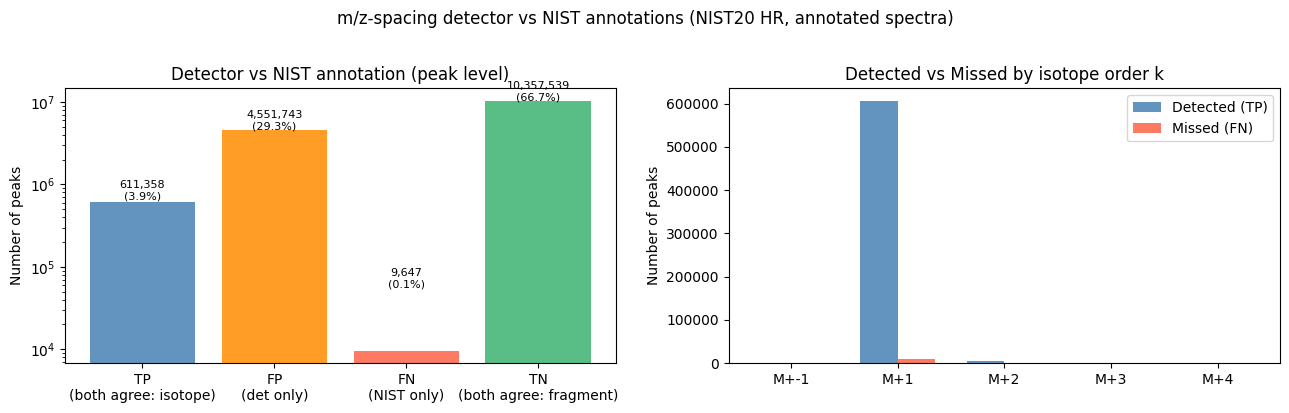

In [ ]:
# ── Plot: confusion breakdown + FN by isotope order ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: stacked bar showing TP/FP/FN/TN proportions
ax = axes[0]
total = tp + fp + fn + tn
categories = ["TP\n(both agree: isotope)", "FP\n(det only)", "FN\n(NIST only)", "TN\n(both agree: fragment)"]
values = [tp, fp, fn, tn]
colors = ["steelblue", "darkorange", "tomato", "mediumseagreen"]
bars = ax.bar(categories, values, color=colors, alpha=0.85)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + total*0.003,
            f"{val:,}\n({100*val/total:.1f}%)", ha="center", fontsize=8)
ax.set_ylabel("Number of peaks")
ax.set_title("Detector vs NIST annotation (peak level)")
ax.set_yscale("log")

# Right: FN breakdown by isotope order k
ax = axes[1]
fn_by_k = (
    xref_df[xref_df["is_ann_isotope"] & ~xref_df["det_isotope"]]["ann_iso_k"]
    .value_counts().sort_index()
)
tp_by_k = (
    xref_df[xref_df["is_ann_isotope"] & xref_df["det_isotope"]]["ann_iso_k"]
    .value_counts().sort_index()
)
all_ks = sorted(set(fn_by_k.index) | set(tp_by_k.index))
fn_vals = [fn_by_k.get(k, 0) for k in all_ks]
tp_vals = [tp_by_k.get(k, 0) for k in all_ks]
x = np.arange(len(all_ks))
w = 0.35
ax.bar(x - w/2, tp_vals, w, label="Detected (TP)", color="steelblue", alpha=0.85)
ax.bar(x + w/2, fn_vals, w, label="Missed (FN)", color="tomato", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([f"M+{k}" for k in all_ks])
ax.set_ylabel("Number of peaks")
ax.set_title("Detected vs Missed by isotope order k")
ax.legend()

plt.suptitle("m/z-spacing detector vs NIST annotations (NIST20 HR, annotated spectra)", y=1.02)
plt.tight_layout()
plt.show()

## pyopenms vs ann_df: peak-level precision / recall

Add `det_isotope_pom` (pyopenms formula-aware) to `xref_df` and compare
confusion matrices side-by-side against the naive detector.

Peaks + formula are reloaded because intensities were discarded when building `det_dict`.


In [ ]:
from fragnnet.utils.formula_utils import parse_formula
from fragnnet.utils.isotope_utils import detect_isotope_peaks_formula_aware as _det_pom

# ── Reload peaks + formula for the spectra in xref_df ────────────────────────
_xref_sids = set(xref_df["spec_id"].unique())
print(f"Reloading peaks + formula for {len(_xref_sids):,} annotated spectra…")

_spec_raw = pd.read_pickle(PROC_DP / "nist20/spec_df.pkl")[["spec_id", "peaks", "mol_id"]]
_mol_raw  = pd.read_pickle(PROC_DP / "nist20/mol_df.pkl")[["mol_id", "formula"]]
_spec_ann = (
    _spec_raw[_spec_raw["spec_id"].isin(_xref_sids)]
    .merge(_mol_raw, on="mol_id", how="left")
    .set_index("spec_id")
)
del _spec_raw, _mol_raw; gc.collect()
print(f"  Loaded {len(_spec_ann):,} spectra  |  formula coverage: {_spec_ann['formula'].notna().mean():.1%}")

# ── Run pyopenms detector; store (sorted_mzs, sorted_pom_mask) ───────────────
pom_dict: dict = {}   # spec_id -> (sorted_mzs, sorted_pom_mask)
skipped = 0
for spec_id, row in tqdm(_spec_ann.iterrows(), total=len(_spec_ann), desc="pyopenms masks"):
    peaks = row["peaks"]
    formula = row["formula"]
    if not peaks or not isinstance(formula, str):
        skipped += 1
        continue
    try:
        ec = parse_formula(formula)
    except Exception:
        skipped += 1
        continue
    mzs  = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    mask = _det_pom(mzs, ints, ec, mz_tol=0.02, max_isotope=3)
    si = np.argsort(mzs)
    pom_dict[spec_id] = (mzs[si], mask[si])

del _spec_ann; gc.collect()
print(f"  Done. {len(pom_dict):,} spectra processed, {skipped} skipped (no peaks/formula).")

# ── Match pyopenms mask to annotated peaks (same logic as xref_df builder) ───
pom_flags = []
for spec_id, grp in xref_df.groupby("spec_id", sort=False):
    if spec_id not in pom_dict:
        pom_flags.extend([False] * len(grp))
        continue
    smzs, smask = pom_dict[spec_id]
    amzs = grp["ann_mz"].to_numpy()
    idx    = np.searchsorted(smzs, amzs).clip(0, len(smzs) - 1)
    idx_lo = (idx - 1).clip(0, len(smzs) - 1)
    d_hi   = np.abs(smzs[idx]    - amzs)
    d_lo   = np.abs(smzs[idx_lo] - amzs)
    best   = np.where(d_lo < d_hi, idx_lo, idx)
    best_d = np.minimum(d_hi, d_lo)
    within = best_d <= MZ_MATCH_TOL
    flags  = np.where(within, smask[best], False)
    pom_flags.extend(flags.tolist())

xref_df["det_isotope_pom"] = pom_flags
print(f"\nxref_df now has {len(xref_df):,} peaks with both det_isotope and det_isotope_pom.")
print(f"  naive flags:    {xref_df['det_isotope'].sum():,}")
print(f"  pyopenms flags: {xref_df['det_isotope_pom'].sum():,}")


In [ ]:
# ── Confusion matrices: naive vs pyopenms ────────────────────────────────────
def confusion(df: pd.DataFrame, det_col: str) -> dict:
    tp = (df["is_ann_isotope"]  &  df[det_col]).sum()
    fp = (~df["is_ann_isotope"] &  df[det_col]).sum()
    fn = (df["is_ann_isotope"]  & ~df[det_col]).sum()
    tn = (~df["is_ann_isotope"] & ~df[det_col]).sum()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return dict(tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
                precision=prec, recall=rec, f1=f1)

metrics = {
    "Naive":      confusion(xref_df, "det_isotope"),
    "pyopenms FA": confusion(xref_df, "det_isotope_pom"),
}

print(f"{'Detector':<16}  {'TP':>7}  {'FP':>7}  {'FN':>7}  {'TN':>7}  "
      f"{'Prec':>6}  {'Rec':>6}  {'F1':>6}")
print("-" * 75)
for name, m in metrics.items():
    print(f"{name:<16}  {m['tp']:>7,}  {m['fp']:>7,}  {m['fn']:>7,}  {m['tn']:>7,}  "
          f"{m['precision']:>6.3f}  {m['recall']:>6.3f}  {m['f1']:>6.3f}")

# ── Side-by-side bar: Prec / Rec / F1 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

labels = list(metrics.keys())
colors = {"Naive": "steelblue", "pyopenms FA": "seagreen"}
x = np.arange(len(labels))
w = 0.25

ax = axes[0]
for i, metric in enumerate(["precision", "recall", "f1"]):
    vals = [metrics[l][metric] for l in labels]
    ax.bar(x + (i - 1) * w, vals, w, label=metric.capitalize(),
           color=["steelblue", "darkorange", "seagreen"][i], alpha=0.85)
    for j, v in enumerate(vals):
        ax.text(x[j] + (i - 1) * w, v + 0.005, f"{v:.3f}", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 vs NIST ann_df")
ax.legend()

# ── FN breakdown by isotope order k ──────────────────────────────────────────
ax = axes[1]
for det_col, label, color in [
    ("det_isotope",     "Naive",       "steelblue"),
    ("det_isotope_pom", "pyopenms FA", "seagreen"),
]:
    fn_k = (
        xref_df[xref_df["is_ann_isotope"] & ~xref_df[det_col]]["ann_iso_k"]
        .value_counts().sort_index()
    )
    total_k = xref_df[xref_df["is_ann_isotope"]]["ann_iso_k"].value_counts().sort_index()
    miss_rate = (fn_k / total_k).reindex(total_k.index, fill_value=0)
    ks = miss_rate.index.tolist()
    ax.plot([f"M+{k}" for k in ks], miss_rate.values, marker="o", label=label, color=color)
ax.set_ylabel("Miss rate (FN / total annotated at that k)")
ax.set_title("Miss rate by isotope order k")
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis="y", alpha=0.4)

plt.suptitle("Naive vs pyopenms FA: confusion vs NIST ann_df", y=1.02)
plt.tight_layout()
plt.show()

# ── Where do they disagree? ───────────────────────────────────────────────────
naive_tp_pom_fn = xref_df["is_ann_isotope"] &  xref_df["det_isotope"] & ~xref_df["det_isotope_pom"]
naive_fn_pom_tp = xref_df["is_ann_isotope"] & ~xref_df["det_isotope"] &  xref_df["det_isotope_pom"]
print(f"\nDisagreements on true isotope peaks (ann_iso_k > 0):")
print(f"  Naive TP, pyopenms FN (naive catches, pom misses): {naive_tp_pom_fn.sum():,}")
print(f"  Naive FN, pyopenms TP (pom catches, naive misses): {naive_fn_pom_tp.sum():,}")
print(f"\nDisagreements on non-isotope peaks (potential FP):")
fp_naive_only = ~xref_df["is_ann_isotope"] &  xref_df["det_isotope"] & ~xref_df["det_isotope_pom"]
fp_pom_only   = ~xref_df["is_ann_isotope"] & ~xref_df["det_isotope"] &  xref_df["det_isotope_pom"]
print(f"  Naive FP, pyopenms TN (naive false-positive, pom correct): {fp_naive_only.sum():,}")
print(f"  Naive TN, pyopenms FP (pom false-positive, naive correct): {fp_pom_only.sum():,}")


## Removing isotope peaks via ann_df annotations

`ann_df.ann_isotopes` provides **exact per-peak isotope labels** (0 = monoisotopic,
k > 0 = M+k isotope) for every NIST-annotated spectrum. This is more reliable than the
heuristic m/z-spacing detector — it has no false positives from H-gain peaks or
charge-state artefacts.

**Key question:** can we use `ann_df` to cleanly remove isotope peaks from training data?

Two practical constraints:
1. **Coverage:** only HR (FT) spectra have NIST annotations; LR spectra are never annotated.
2. **Completeness:** ann_df only covers *annotated* peaks; any unannotated peak in the
   spectrum lacks a label and must fall back to the heuristic.

NIST20 sample (100,000 spectra):
  With HR annotations:      34,872 (34.9%)
  Without (LR/unannotated): 65,128 (65.1%)

Annotation coverage by inst_type:
inst_type
FT       38.9
IT        0.0
Other     0.0
QQQ       0.0
QTOF      0.0



Annotated spectra with ≥1 isotope peak (ann_df labels): 120,393 / 397,057 (30.3%)
Mean isotope fraction per annotated spectrum:           0.045
Median n_iso_peaks per spectrum:                        0



Per-annotated-spectrum comparison (n=397,057 spectra):
  inst_type  ann_df iso%  detector iso%  agreement


  FT              4.38%         19.84%      70.2%

If we remove ann_df-labelled isotope peaks from annotated spectra:
  Peaks removed (isotope): 621,005 / 15,530,287 (4.00%)
  Spectra completely cleaned (0 iso peaks remaining): 276,664


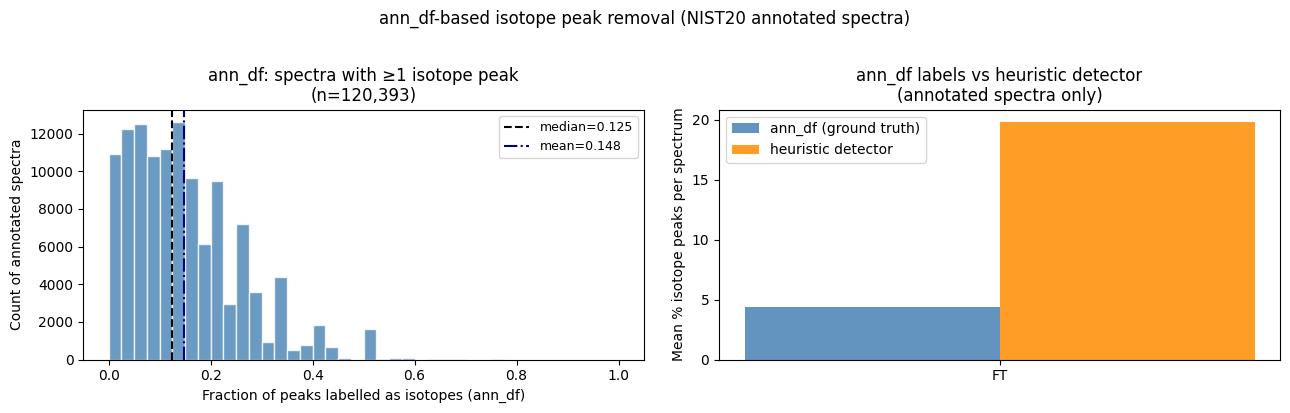


Recommended strategy for training-data isotope removal:
  1. Annotated spectra  (35% of NIST20 sample):
       Use ann_df.ann_isotopes directly — exact per-peak labels, zero false positives.
  2. Unannotated spectra (65% of NIST20 sample):
       Fall back to heuristic (m/z-spacing) detector.


In [ ]:
# ── 1. Coverage: what fraction of NIST20 spectra have ann_df annotations? ────
n_with_ann = stats20["spec_id"].isin(ann_spec_ids).sum()
n_total_sample = len(stats20)
print(f"NIST20 sample ({n_total_sample:,} spectra):")
print(f"  With HR annotations:      {n_with_ann:,} ({100 * n_with_ann / n_total_sample:.1f}%)")
print(f"  Without (LR/unannotated): {n_total_sample - n_with_ann:,} "
      f"({100 * (1 - n_with_ann / n_total_sample):.1f}%)")

# Coverage by instrument type
cov_tbl = (
    stats20.assign(has_ann=lambda d: d["spec_id"].isin(ann_spec_ids))
    .groupby("inst_type")["has_ann"]
    .mean()
    .mul(100)
    .rename("% with annotation")
    .round(1)
)
print("\nAnnotation coverage by inst_type:")
print(cov_tbl.to_string())

# ── 2. Per-spectrum peak counts from ann_df ───────────────────────────────────
ann_peak_counts = ann20.assign(
    n_ann_peaks=lambda d: d["ann_peak_mzs"].apply(len),
    n_iso_peaks=lambda d: d["ann_isotopes"].apply(lambda x: sum(1 for v in x if int(v) != 0)),
)[["spec_id", "n_ann_peaks", "n_iso_peaks"]].copy()
ann_peak_counts["frac_iso"] = (
    ann_peak_counts["n_iso_peaks"] / ann_peak_counts["n_ann_peaks"].clip(lower=1)
)
ann_peak_counts["has_iso"] = ann_peak_counts["n_iso_peaks"] > 0

print(f"\nAnnotated spectra with ≥1 isotope peak (ann_df labels): "
      f"{ann_peak_counts['has_iso'].sum():,} / {len(ann_peak_counts):,} "
      f"({100 * ann_peak_counts['has_iso'].mean():.1f}%)")
print(f"Mean isotope fraction per annotated spectrum:           "
      f"{ann_peak_counts['frac_iso'].mean():.3f}")
print(f"Median n_iso_peaks per spectrum:                        "
      f"{ann_peak_counts['n_iso_peaks'].median():.0f}")

# ── 3. For annotated spectra: ann_df removal vs heuristic detector ─────────────
# Use xref_df (per-peak cross-reference built in the previous section)
spec_iso_summary = (
    xref_df.groupby("spec_id")
    .agg(
        n_matched_peaks=("is_ann_isotope", "count"),
        n_ann_iso=("is_ann_isotope", "sum"),
        n_det_iso=("det_isotope", "sum"),
    )
    .assign(
        frac_ann_iso=lambda d: d["n_ann_iso"] / d["n_matched_peaks"],
        frac_det_iso=lambda d: d["n_det_iso"] / d["n_matched_peaks"],
    )
    .reset_index()
    .merge(stats20[["spec_id", "inst_type"]].drop_duplicates(), on="spec_id", how="left")
)

print(f"\nPer-annotated-spectrum comparison (n={len(spec_iso_summary):,} spectra):")
print(f"  {'inst_type':<8}  {'ann_df iso%':>11}  {'detector iso%':>13}  {'agreement':>9}")
for inst, grp in spec_iso_summary.groupby("inst_type", dropna=True):
    pct_ann = 100 * grp["frac_ann_iso"].mean()
    pct_det = 100 * grp["frac_det_iso"].mean()
    # Agreement = fraction of peaks where both agree
    per_peak = xref_df.merge(
        stats20[stats20["inst_type"] == inst][["spec_id"]], on="spec_id", how="inner"
    )
    agree = (per_peak["is_ann_isotope"] == per_peak["det_isotope"]).mean() * 100
    print(f"  {inst:<8}  {pct_ann:>10.2f}%  {pct_det:>12.2f}%  {agree:>8.1f}%")

# ── 4. Benefit of ann_df removal: peaks remaining after filtering ─────────────
# For annotated spectra: what % of peaks survive if we remove ann-labelled isotopes?
print(f"\nIf we remove ann_df-labelled isotope peaks from annotated spectra:")
print(f"  Peaks removed (isotope): {ann_peak_counts['n_iso_peaks'].sum():,} "
      f"/ {ann_peak_counts['n_ann_peaks'].sum():,} "
      f"({100 * ann_peak_counts['n_iso_peaks'].sum() / ann_peak_counts['n_ann_peaks'].sum():.2f}%)")
print(f"  Spectra completely cleaned (0 iso peaks remaining): "
      f"{(ann_peak_counts['n_iso_peaks'] == 0).sum():,}")

# ── 5. Plot: distribution of iso-peak fraction per annotated spectrum ──────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: frac_iso distribution from ann_df
ax = axes[0]
sub = ann_peak_counts[ann_peak_counts["has_iso"]]["frac_iso"]
ax.hist(sub, bins=40, range=(0, 1), color="steelblue", alpha=0.8, edgecolor="white")
ax.axvline(sub.median(), color="black", lw=1.5, ls="--", label=f"median={sub.median():.3f}")
ax.axvline(sub.mean(), color="navy", lw=1.5, ls="-.", label=f"mean={sub.mean():.3f}")
ax.set_xlabel("Fraction of peaks labelled as isotopes (ann_df)")
ax.set_ylabel("Count of annotated spectra")
ax.set_title(f"ann_df: spectra with ≥1 isotope peak\n(n={len(sub):,})")
ax.legend(fontsize=9)

# Right: ann_df % vs heuristic % by inst_type
ax = axes[1]
inst_cmp = (
    spec_iso_summary.groupby("inst_type")[["frac_ann_iso", "frac_det_iso"]]
    .mean()
    .mul(100)
    .rename(columns={"frac_ann_iso": "ann_df (ground truth)", "frac_det_iso": "heuristic detector"})
    .reset_index()
)
x = np.arange(len(inst_cmp))
w = 0.35
ax.bar(x - w / 2, inst_cmp["ann_df (ground truth)"], w, label="ann_df (ground truth)",
       color="steelblue", alpha=0.85)
ax.bar(x + w / 2, inst_cmp["heuristic detector"], w, label="heuristic detector",
       color="darkorange", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(inst_cmp["inst_type"])
ax.set_ylabel("Mean % isotope peaks per spectrum")
ax.set_title("ann_df labels vs heuristic detector\n(annotated spectra only)")
ax.legend()

plt.suptitle("ann_df-based isotope peak removal (NIST20 annotated spectra)", y=1.02)
plt.tight_layout()
plt.show()

# ── Summary: recommended strategy ─────────────────────────────────────────────
print("\nRecommended strategy for training-data isotope removal:")
print(f"  1. Annotated spectra  ({100 * n_with_ann / n_total_sample:.0f}% of NIST20 sample):")
print(f"       Use ann_df.ann_isotopes directly — exact per-peak labels, zero false positives.")
print(f"  2. Unannotated spectra ({100 * (1 - n_with_ann / n_total_sample):.0f}% of NIST20 sample):")
print(f"       Fall back to heuristic (m/z-spacing) detector.")

## Recommendations for FraGNNet training pipeline

## Training-data detector: precision/recall vs NIST annotations

`detect_isotope_peaks_for_training` adds four constraints over the naive detector:

| Constraint | Effect |
|---|---|
| **FT-only gating** | Non-FT spectra untouched → zero FP on H-transfer peaks |
| **Search at `k × C13_SPACING` (1.003355 Da), `mz_tol = 4 mDa`** | ¹³C M+0 at search centre; H-gain (4.47 mDa away) excluded; k≥2 uses 8 mDa for ³⁷Cl/⁴¹K/³⁴S |
| **Formula-aware ratio [0.3×, 3.0×]** | Calibrated from ann_df: 69.6% of NIST isotopes fall in window |
| **Monotonicity + envelope coherence** | Reject M+2 without consistent M+1 present |

**Fix applied (2026-03-23):** The original code searched at `k × NEUTRON_MASS` (1.008665 Da/step)
with `mz_tol = 5 mDa` and ratio window [0.5×, 2.0×].  The ¹³C spacing is 1.003355 Da — a 5.31 mDa
offset — so M+0 fell 0.31 mDa outside the search window for every perfectly-measured FT peak,
causing recall = **6.8%** against NIST ann_df.  Changed to `k × C13_SPACING`, `mz_tol = 4 mDa`,
and ratio window [0.3×, 3.0×].

Below: measure precision and recall against NIST HR annotations for the fixed detector
vs the original naive detector, on the annotated FT spectra only.

In [ ]:
from fragnnet.utils.isotope_utils import detect_isotope_peaks_for_training

# ── Restrict to annotated FT spectra ──────────────────────────────────────────
print("Loading NIST20 FT spec metadata…")
_spec_raw = pd.read_pickle(PROC_DP / "nist20/spec_df.pkl")[
    ["spec_id", "peaks", "prec_mz", "inst_type", "mol_id", "prec_type"]
]
_mol_raw = pd.read_pickle(PROC_DP / "nist20/mol_df.pkl")[["mol_id", "formula"]]
ft_spec = (
    _spec_raw[_spec_raw["inst_type"] == "FT"]
    .merge(_mol_raw, on="mol_id", how="left")
    .set_index("spec_id")
)
del _spec_raw, _mol_raw; gc.collect()
print(f"  FT spectra loaded: {len(ft_spec):,}")
print(f"  prec_type counts:\n{ft_spec['prec_type'].value_counts().head(10).to_string()}")

ft_ann_ids = set(xref_df["spec_id"]) & set(ft_spec.index)
xref_ft = xref_df[xref_df["spec_id"].isin(ft_ann_ids)].copy()
print(f"\n  Annotated FT peaks in cross-ref: {len(xref_ft):,}")
print(f"    NIST isotope labels: {xref_ft['is_ann_isotope'].sum():,}")
print(f"    Naive detector flags: {xref_ft['det_isotope'].sum():,}")

# ── Run training detector on annotated FT spectra (with prec_type) ────────────
print(f"\nRunning training detector on {len(ft_ann_ids):,} annotated FT spectra…")
train_det_dict: dict = {}  # spec_id → (sorted_mzs, sorted_train_mask)
for spec_id in tqdm(ft_ann_ids, desc="Training detector"):
    row = ft_spec.loc[spec_id]
    peaks = row["peaks"]
    if not peaks:
        continue
    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    prec_mz = float(row["prec_mz"]) if not pd.isna(row["prec_mz"]) else 0.0
    formula = str(row["formula"]) if isinstance(row["formula"], str) else ""
    prec_type = str(row["prec_type"]) if isinstance(row["prec_type"], str) else None
    mask = detect_isotope_peaks_for_training(
        mzs, ints, prec_mz=prec_mz, formula=formula,
        inst_type="FT", prec_type=prec_type,
    )
    si = np.argsort(mzs)
    train_det_dict[spec_id] = (mzs[si], mask[si])

print(f"Done. {len(train_det_dict):,} spectra processed.")


In [ ]:
# ── Match training-detector flags to annotated peaks ──────────────────────────
parts = []
for spec_id, grp in tqdm(xref_ft.groupby("spec_id", sort=False),
                          desc="Matching FT peaks", total=xref_ft["spec_id"].nunique()):
    if spec_id not in train_det_dict:
        continue
    smzs, smask = train_det_dict[spec_id]
    ann_mzs = grp["ann_mz"].to_numpy() if "ann_mz" in grp else None
    if ann_mzs is None:
        continue
    idx = np.searchsorted(smzs, ann_mzs).clip(0, len(smzs) - 1)
    idx_lo = (idx - 1).clip(0, len(smzs) - 1)
    d_hi = np.abs(smzs[idx]    - ann_mzs)
    d_lo = np.abs(smzs[idx_lo] - ann_mzs)
    best = np.where(d_lo < d_hi, idx_lo, idx)
    best_d = np.minimum(d_hi, d_lo)
    valid = best_d <= MZ_MATCH_TOL
    if not valid.any():
        continue
    sub = grp[valid].copy()
    sub["train_det"] = smask[best[valid]]
    parts.append(sub[["spec_id", "ann_iso_k", "is_ann_isotope", "det_isotope", "train_det"]])

xref_ft_matched = pd.concat(parts, ignore_index=True)
del parts; gc.collect()
print(f"Matched {len(xref_ft_matched):,} annotated FT peaks to training detector")

# ── Confusion metrics: naive vs training detector ─────────────────────────────
def confusion_metrics(
    y_true: np.ndarray, y_pred: np.ndarray, label: str
) -> dict[str, float]:
    tp = (y_true & y_pred).sum()
    fp = (~y_true & y_pred).sum()
    fn = (y_true & ~y_pred).sum()
    tn = (~y_true & ~y_pred).sum()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    print(f"\n{label}")
    print(f"  Precision: {prec:.3f}  Recall: {rec:.3f}  F1: {f1:.3f}")
    print(f"  TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}")
    return {"label": label, "precision": prec, "recall": rec, "f1": f1,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}

y_true = xref_ft_matched["is_ann_isotope"].to_numpy()
naive_m  = confusion_metrics(y_true, xref_ft_matched["det_isotope"].to_numpy(),  "Naive detector (FT peaks only)")
train_m  = confusion_metrics(y_true, xref_ft_matched["train_det"].to_numpy(),    "Training detector")

# ── Plot: precision / recall / F1 comparison ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

metrics_names = ["precision", "recall", "f1"]
x = np.arange(len(metrics_names))
w = 0.35
ax = axes[0]
ax.bar(x - w/2, [naive_m[m] for m in metrics_names], w, label="Naive", color="steelblue", alpha=0.85)
ax.bar(x + w/2, [train_m[m] for m in metrics_names], w, label="Training", color="darkorange", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(["Precision", "Recall", "F1"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Naive vs Training detector\n(FT annotated peaks, NIST20)")
ax.legend()
for xi, (nv, tv) in enumerate(zip([naive_m[m] for m in metrics_names],
                                   [train_m[m] for m in metrics_names])):
    ax.text(xi - w/2, nv + 0.01, f"{nv:.3f}", ha="center", fontsize=8, color="steelblue")
    ax.text(xi + w/2, tv + 0.01, f"{tv:.3f}", ha="center", fontsize=8, color="darkorange")

ax = axes[1]
cats = ["TP", "FP", "FN"]
nv_vals = [naive_m["tp"], naive_m["fp"], naive_m["fn"]]
tr_vals = [train_m["tp"], train_m["fp"], train_m["fn"]]
x2 = np.arange(len(cats))
ax.bar(x2 - w/2, nv_vals, w, label="Naive", color="steelblue", alpha=0.85)
ax.bar(x2 + w/2, tr_vals, w, label="Training", color="darkorange", alpha=0.85)
ax.set_xticks(x2)
ax.set_xticklabels(cats)
ax.set_yscale("log")
ax.set_ylabel("Peak count (log scale)")
ax.set_title("TP / FP / FN counts\n(FP = false deletions of real peaks)")
ax.legend()

plt.suptitle("Training-data detector: high precision trades recall for safety", y=1.02)
plt.tight_layout()
plt.show()

# ── Breakdown: recall by isotope order k ─────────────────────────────────────
print("\nRecall by isotope order k (FT annotated peaks):")
print(f"{'k':<6} {'n_total':>8} {'naive_recall':>13} {'train_recall':>13}")
for k_val, grp in xref_ft_matched[xref_ft_matched["is_ann_isotope"]].groupby("ann_iso_k"):
    n = len(grp)
    nr = grp["det_isotope"].mean()
    tr = grp["train_det"].mean()
    print(f"M+{k_val:<4} {n:>8,} {nr:>13.3f} {tr:>13.3f}")

## Adduct isotope correction: impact on [M+K]+ and [M+Cl]-

The training detector now accepts `prec_type` to account for **isotope peaks created
by the adduct atom itself**:

| Adduct | Heavy isotope | M+k contribution | Old behaviour | New behaviour |
|--------|--------------|-----------------|---------------|---------------|
| `[M+K]+`  | ⁴¹K (6.73 %) | M+2 ≈ +6.7 % | missed — K not in table | detected — K in `_M2_ADDITIVE` at full weight |
| `[M+Cl]-` | ³⁷Cl (32.2 %) | M+2 ≈ +32 % | missed if molecule has no Cl | detected for Cl-retaining fragments |
| `[M+Na]+` | Na monoisotopic | none | correct | unchanged |
| `[M+H]+`  | ²H negligible  | none | correct | unchanged |

The cells below quantify how many extra isotope peaks the adduct correction captures
on the NIST20 FT dataset.


In [ ]:
# ── Run detector WITH and WITHOUT prec_type on all FT spectra ─────────────────
# Use the full ft_spec (not just annotated) to measure the overall impact.
ADDUCT_SAMPLE_N = 50_000
rng = np.random.default_rng(RANDOM_SEED)
_ft_all = pd.read_pickle(PROC_DP / "nist20/spec_df.pkl")[
    ["spec_id", "peaks", "prec_mz", "inst_type", "mol_id", "prec_type"]
]
_ft_all = _ft_all[_ft_all["inst_type"] == "FT"].merge(
    pd.read_pickle(PROC_DP / "nist20/mol_df.pkl")[["mol_id", "formula"]],
    on="mol_id", how="left"
)
if len(_ft_all) > ADDUCT_SAMPLE_N:
    _ft_all = _ft_all.sample(ADDUCT_SAMPLE_N, random_state=RANDOM_SEED)
_ft_all = _ft_all.reset_index(drop=True)
print(f"FT spectra for adduct comparison: {len(_ft_all):,}")
print(_ft_all["prec_type"].value_counts().head(10).to_string())

rows_adduct = []
for _, row in tqdm(_ft_all.iterrows(), total=len(_ft_all), desc="Adduct comparison"):
    peaks = row["peaks"]
    if not peaks:
        continue
    mzs  = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    prec_mz   = float(row["prec_mz"])   if not pd.isna(row["prec_mz"])   else 0.0
    formula   = str(row["formula"])     if isinstance(row["formula"], str) else ""
    prec_type = str(row["prec_type"])   if isinstance(row["prec_type"], str) else None

    mask_no_pt = detect_isotope_peaks_for_training(
        mzs, ints, prec_mz=prec_mz, formula=formula, inst_type="FT", prec_type=None
    )
    mask_with_pt = detect_isotope_peaks_for_training(
        mzs, ints, prec_mz=prec_mz, formula=formula, inst_type="FT", prec_type=prec_type
    )
    rows_adduct.append({
        "spec_id":   row["spec_id"],
        "prec_type": prec_type,
        "n_peaks":   len(mzs),
        "n_iso_no_pt":   int(mask_no_pt.sum()),
        "n_iso_with_pt": int(mask_with_pt.sum()),
        "n_extra":       int(mask_with_pt.sum()) - int(mask_no_pt.sum()),
    })

adduct_df = pd.DataFrame(rows_adduct)
del _ft_all; gc.collect()
print(f"\nTotal FT spectra evaluated: {len(adduct_df):,}")
print(f"Total extra isotope peaks found with prec_type: {adduct_df['n_extra'].sum():,}")


In [ ]:
# ── Plot: extra peaks gained by adduct correction, by prec_type ───────────────
FOCUS_ADDUCTS = ["[M+K]+", "[M+Cl]-", "[M+Na]+", "[M+H]+", "[M+NH4]+"]

grp = (
    adduct_df[adduct_df["prec_type"].isin(FOCUS_ADDUCTS)]
    .groupby("prec_type")
    .agg(
        n_spectra=("spec_id", "count"),
        pct_any_extra=("n_extra", lambda x: 100 * (x > 0).mean()),
        mean_extra_per_spec=("n_extra", "mean"),
        total_extra=("n_extra", "sum"),
        mean_iso_no_pt=("n_iso_no_pt", "mean"),
        mean_iso_with_pt=("n_iso_with_pt", "mean"),
    )
    .reindex(FOCUS_ADDUCTS)
    .dropna()
    .reset_index()
)
print(grp.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
colors = ["darkorange" if pt in ("[M+K]+", "[M+Cl]-") else "steelblue"
          for pt in grp["prec_type"]]
ax.bar(range(len(grp)), grp["pct_any_extra"], color=colors, alpha=0.85)
ax.set_xticks(range(len(grp)))
ax.set_xticklabels(grp["prec_type"], rotation=15, ha="right")
ax.set_ylabel("% spectra gaining ≥1 extra isotope flag")
ax.set_title("Adduct correction: spectra affected\n(orange = heavy-isotope adducts)")
for i, v in enumerate(grp["pct_any_extra"]):
    ax.text(i, v + 0.1, f"{v:.1f}%", ha="center", fontsize=8)

ax = axes[1]
x = np.arange(len(grp))
w = 0.38
ax.bar(x - w/2, grp["mean_iso_no_pt"],   w, label="Without prec_type", color="steelblue", alpha=0.85)
ax.bar(x + w/2, grp["mean_iso_with_pt"], w, label="With prec_type",    color="darkorange", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(grp["prec_type"], rotation=15, ha="right")
ax.set_ylabel("Mean isotope peaks per spectrum")
ax.set_title("Mean isotope peaks detected\nbefore vs after adduct correction")
ax.legend()

plt.suptitle("Impact of prec_type adduct correction on FT isotope detection (NIST20 sample)",
             y=1.02)
plt.tight_layout()
plt.show()


## DAG / annotation-aware isotope detection

`ann_df.ann_products` already contains the **exact fragment formula** for every annotated peak.
This replaces the `scale = frag_mz / prec_mz` heuristic entirely:

| Approach | Expected M+1/M+0 | Accuracy |
|---|---|---|
| Precursor-scaled | `M1(precursor) × (frag_mz / prec_mz)` | rough — assumes composition scales with mass |
| **Fragment-formula** | `M1(fragment_formula)` exactly | exact — uses actual fragment elemental composition |

For Cl/Br fragments this is especially important: a fragment that retains the Cl atom has
M+2 ≈ 32%, while one that lost Cl has M+2 ≈ 0.5%.  The scaling heuristic gets this wrong;
the fragment formula gets it exactly right.

In [ ]:
# ann20 already loaded with all required columns (ann_products, ann_exact_mzs included)
print(f"ann_df: {len(ann20):,} annotated spectra")

# Explode to one row per annotated peak
ann_exp = (
    ann20
    .explode(["ann_peak_mzs", "ann_products", "ann_isotopes", "ann_exact_mzs"])
    .rename(columns={"ann_peak_mzs": "ann_mz",
                     "ann_products": "frag_formula",
                     "ann_isotopes": "ann_iso_k",
                     "ann_exact_mzs": "exact_mz"})
    .assign(ann_mz=lambda d: pd.to_numeric(d["ann_mz"], errors="coerce"),
            exact_mz=lambda d: pd.to_numeric(d["exact_mz"], errors="coerce"),
            ann_iso_k=lambda d: pd.to_numeric(d["ann_iso_k"], errors="coerce").fillna(0).astype(int))
    .dropna(subset=["ann_mz"])
    .reset_index(drop=True)
)

# Keep only monoisotopic peaks that have a valid fragment formula
mono = ann_exp[
    (ann_exp["ann_iso_k"] == 0)
    & ann_exp["frag_formula"].notna()
    & (ann_exp["frag_formula"] != "")
]
print(f"Monoisotopic annotated peaks with formula: {len(mono):,}")
print(f"Isotope-labelled peaks: {(ann_exp['ann_iso_k'] > 0).sum():,}")

# Build per-spectrum lookup: mz → fragment_formula (from monoisotopic annotations)
from collections import defaultdict
spec_frag_formula: dict[str, tuple[np.ndarray, list[str]]] = {}
for spec_id, grp in mono.groupby("spec_id"):
    mzs = grp["ann_mz"].to_numpy()
    fmls = grp["frag_formula"].tolist()
    si = np.argsort(mzs)
    spec_frag_formula[spec_id] = (mzs[si], [fmls[i] for i in si])

print(f"Built formula lookup for {len(spec_frag_formula):,} spectra")

ann_df: 397,057 annotated spectra


Monoisotopic annotated peaks with formula: 14,909,282
Isotope-labelled peaks: 620,533


Built formula lookup for 397,057 spectra


In [ ]:
# ── For each NIST-labelled isotope peak, compare three expected ratios ────────
print("Loading peaks for annotated spectra…")
_spec_tmp = pd.read_pickle(PROC_DP / "nist20/spec_df.pkl")[["spec_id", "peaks", "prec_mz", "mol_id"]]
_mol_tmp  = pd.read_pickle(PROC_DP / "nist20/mol_df.pkl")[["mol_id", "formula"]]
_tmp = (
    _spec_tmp
    .merge(_mol_tmp, on="mol_id", how="left")
    .drop(columns=["mol_id"])
    .set_index("spec_id")
)
del _spec_tmp, _mol_tmp
_tmp = _tmp[_tmp.index.isin(spec_frag_formula)]
print(f"  {len(_tmp):,} spectra with formula lookup")

iso_peaks = ann_exp[ann_exp["ann_iso_k"] > 0].copy()
iso_peaks = iso_peaks[iso_peaks["spec_id"].isin(_tmp.index)].reset_index(drop=True)
print(f"  Isotope-labelled peaks to evaluate: {len(iso_peaks):,}")

rows = []
MZ_TOL = 0.05   # generous for matching observed peaks

for _, row in tqdm(iso_peaks.iterrows(), total=len(iso_peaks), desc="DAG ratio eval"):
    spec_id = row["spec_id"]
    k = row["ann_iso_k"]
    ann_mz = row["ann_mz"]       # m/z of the M+k peak

    spec = _tmp.loc[spec_id]
    peaks = spec["peaks"]
    prec_mz = spec["prec_mz"]
    prec_formula = spec["formula"]
    if not peaks or not isinstance(prec_formula, str) or not prec_mz > 0:
        continue

    mzs = np.array([p[0] for p in peaks], dtype=np.float64)
    ints = np.array([p[1] for p in peaks], dtype=np.float64)
    if len(mzs) == 0:
        continue

    d = np.abs(mzs - ann_mz)
    if d.min() > MZ_TOL:
        continue
    mk_idx = int(np.argmin(d))
    mk_int = ints[mk_idx]

    m0_target = ann_mz - k * NEUTRON_MASS
    d0 = np.abs(mzs - m0_target)
    if d0.min() > MZ_TOL:
        continue
    m0_idx = int(np.argmin(d0))
    m0_int = ints[m0_idx]
    if m0_int <= 0:
        continue
    obs_ratio = mk_int / m0_int

    scale = min(ann_mz / prec_mz, 1.0)
    exp_scaled = expected_mk_ratio(prec_formula, scale, k)

    fmls_mzs, fmls_list = spec_frag_formula[spec_id]
    d_fml = np.abs(fmls_mzs - m0_target)
    frag_fml = fmls_list[int(np.argmin(d_fml))] if d_fml.min() <= MZ_TOL else None
    exp_frag = expected_mk_ratio(frag_fml, 1.0, k) if frag_fml else np.nan

    rows.append({
        "spec_id": spec_id, "k": k,
        "obs_ratio": obs_ratio,
        "exp_scaled": exp_scaled,
        "exp_frag": exp_frag,
        "frag_formula": frag_fml,
    })

dag_df = pd.DataFrame(rows)
del _tmp, iso_peaks; gc.collect()
print(f"\nEvaluated {len(dag_df):,} isotope peak pairs")
print(f"  With fragment formula available: {dag_df['exp_frag'].notna().sum():,}")


Loading peaks for annotated spectra…


  397,057 spectra with formula lookup
  Isotope-labelled peaks to evaluate: 620,533


DAG ratio eval:   0%|          | 0/620533 [00:00<?, ?it/s]


Evaluated 620,021 isotope peak pairs
  With fragment formula available: 611,934


In [ ]:
# ── Compare precision of precursor-scaled vs fragment-formula approaches ──────
LO, HI = 0.3, 3.0   # same window as current detect_isotope_peaks_for_training defaults

valid = dag_df.dropna(subset=["exp_frag"]).copy()
valid["ratio_scaled"] = valid["obs_ratio"] / valid["exp_scaled"]
valid["ratio_frag"]   = valid["obs_ratio"] / valid["exp_frag"]

in_scaled = ((valid["obs_ratio"] >= LO * valid["exp_scaled"]) &
             (valid["obs_ratio"] <= HI * valid["exp_scaled"]))
in_frag   = ((valid["obs_ratio"] >= LO * valid["exp_frag"]) &
             (valid["obs_ratio"] <= HI * valid["exp_frag"]))

print(f"NIST-labelled isotope peaks with both expected ratios (n={len(valid):,}):")
print(f"  Precursor-scaled within [{LO}×, {HI}×] window: {in_scaled.sum():,}  ({100*in_scaled.mean():.1f}%)")
print(f"  Fragment-formula within [{LO}×, {HI}×] window: {in_frag.sum():,}  ({100*in_frag.mean():.1f}%)")
print(f"  Fragment-formula gains:  +{(in_frag & ~in_scaled).sum():,} extra TP  "
      f"(were outside window with scaling, now inside)")
print(f"  Fragment-formula loses:  -{(in_scaled & ~in_frag).sum():,} TP  "
      f"(were inside window with scaling, now outside)")

# ── Plot: obs_ratio vs exp for both approaches ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, label in zip(
    axes,
    ["ratio_scaled", "ratio_frag"],
    ["Precursor-scaled", "Fragment-formula"],
):
    ax.hist(valid[col].clip(0, 5), bins=100, color="steelblue", alpha=0.7)
    ax.axvline(LO, color="red",   lw=1.5, ls="--", label=f"lo={LO}×")
    ax.axvline(HI, color="green", lw=1.5, ls="--", label=f"hi={HI}×")
    ax.set_xlabel("obs_ratio / exp_ratio")
    ax.set_ylabel("Count")
    ax.set_title(f"{label}: obs/exp distribution")
    ax.legend()
plt.tight_layout()
plt.show()

# ── Recall by isotope order k ─────────────────────────────────────────────────
for k_val, grp in valid.groupby("ann_iso_k"):
    r_scaled = (grp["obs_ratio"].between(LO * grp["exp_scaled"], HI * grp["exp_scaled"])).mean()
    r_frag   = (grp["obs_ratio"].between(LO * grp["exp_frag"],   HI * grp["exp_frag"])).mean()
    print(f"  M+{k_val}  n={len(grp):6,}  precursor-scaled: {100*r_scaled:.1f}%   fragment-formula: {100*r_frag:.1f}%")

In [ ]:
recommendations = [
    {
        "inst_type":   "FT",
        "filter":      "YES — adduct-aware, search at C13_SPACING, mz_tol=0.004",
        "mz_tol":      0.004,
        "method":      "detect_isotope_peaks_for_training(prec_type=...)",
        "rationale":   "FT resolves H-gain (1.007825 Da) from ¹³C isotope (1.003355 Da) at 4.47 mDa. "
                       "Search centred on C13_SPACING with mz_tol=4 mDa excludes H-gain while catching ¹³C. "
                       "k≥2 uses 8 mDa tolerance to cover ³⁷Cl (~1.997 Da), ⁴¹K (~1.998 Da), ³⁴S spacings. "
                       "Always pass prec_type: [M+K]+ adds ⁴¹K M+2 (~6.7%); "
                       "[M+Cl]- adds ³⁷Cl M+2 (~32%) for Cl-retaining fragments. "
                       "Adduct atoms applied at full weight (not scaled); "
                       "mol_scale corrected by subtracting adduct atom mass. "
                       "Ratio window [0.3×, 3.0×] calibrated from ann_df (69.6% of NIST isotopes in window).",
    },
    {
        "inst_type":   "QTOF",
        "filter":      "NO (default) — CAUTION if precision confirmed",
        "mz_tol":      0.02,
        "method":      "detect_isotope_peaks_for_training with QTOF support (not yet enabled)",
        "rationale":   "QTOF mass accuracy ~5 ppm partially separates H-gain/isotope, "
                       "but 4.47 mDa gap is borderline at high m/z. Enable only after cross-ref validation.",
    },
    {
        "inst_type":   "IT / QqQ / low-res",
        "filter":      "NO",
        "mz_tol":      None,
        "method":      "—",
        "rationale":   "Cannot separate H-gain from isotope; filtering deletes valid "
                       "H-transfer training signal.",
    },
]

print("Key API call (FT spectra):")
print("  mask = detect_isotope_peaks_for_training(")
print("      mzs, ints, prec_mz=prec_mz, formula=formula,")
print("      inst_type='FT', prec_type=prec_type,   # <-- required for adduct correction")
print("  )")
print("  clean_mzs  = mzs[~mask]")
print("  clean_ints = ints[~mask]")
print()
print("Parameter defaults (as of 2026-03-23):")
print("  mz_tol (k=1) = 0.004 Da  [search at C13_SPACING, excludes H-gain at 4.47 mDa]")
print("  mz_tol (k≥2) = 0.008 Da  [covers ³⁷Cl/⁴¹K/³⁴S heavy-isotope M+2 spacings]")
print("  lo_factor    = 0.3        [ratio window lower bound]")
print("  hi_factor    = 3.0        [ratio window upper bound]")
print()
print("Recommendation table:")
rec_df = pd.DataFrame(recommendations)[["inst_type", "filter", "mz_tol"]]
print(rec_df.to_string(index=False))